<a href="https://colab.research.google.com/github/SamPurna023/ANPR/blob/main/stage2_yolo26_vs_yolov8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stage 2 — YOLO26n vs YOLOv8n plate detector (fair comparison)
**Edge ANPR: Raspberry Pi 5 + Hailo-8L**

Dataset: Roboflow `sa-dx8nu/plate-detect` **v1** (same as the YOLOv8n baseline: 3,081 train / 579 valid / 195 test, classes `licence`, `plate`).

**Fairness rule:** both models are trained *in this notebook*, in the same Colab session, with the same Ultralytics version, GPU, dataset version, image size (640), epochs (32), batch (16), patience, seed and default augmentation. The **only** thing that changes is the starting weights (`yolov8n.pt` vs `yolo26n.pt`).

Why retrain YOLOv8n instead of reusing the old 91.9 %? Different library versions or a different GPU session can move mAP by a point or two. Training both side by side removes those hidden variables, so any difference you report is caused by the architecture.

**Before running:** Runtime → Change runtime type → **T4 GPU**. Add `ROBOFLOW_API_KEY` in Colab Secrets (key icon) with notebook access on. Results are saved to Google Drive so a disconnect does not lose them.

Expected total runtime: roughly 45–70 min on a T4 (two 32-epoch runs).

## 0. Environment setup
Checks the GPU and installs Ultralytics (YOLO26 needs Ultralytics ≥ 8.4), Roboflow, ONNX tools. The printed versions go into your report's *Experimental setup* table.

In [4]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip -q install -U ultralytics roboflow onnx onnxslim onnxruntime
import ultralytics, torch, platform
ultralytics.checks()
print('ultralytics', ultralytics.__version__, '| torch', torch.__version__, '| python', platform.python_version())

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.3/112.6 GB disk)
ultralytics 8.4.202 | torch 2.11.0+cu130 | python 3.13.16


## 0b. Mount Google Drive
All runs, weights and the results table are written to `MyDrive/edge_anpr/stage2`.

In [5]:
from google.colab import drive
drive.mount('/content/drive')
import os
OUT = '/content/drive/MyDrive/edge_anpr/stage2'
os.makedirs(OUT, exist_ok=True)
print('saving to', OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
saving to /content/drive/MyDrive/edge_anpr/stage2


## 1. Download the same dataset version
`VERSION = 1` is pinned on purpose — the baseline used v1. If Roboflow ever publishes v2, do **not** change this for the comparison.

In [6]:
from roboflow import Roboflow
try:
    from google.colab import userdata
    API_KEY = userdata.get('ROBOFLOW_API_KEY')
except Exception:
    import getpass
    API_KEY = getpass.getpass('Roboflow API key: ')

VERSION = 1
rf = Roboflow(api_key=API_KEY)
dataset = rf.workspace('sa-dx8nu').project('plate-detect').version(VERSION).download(
    'yolov8', location='/content/plate-detect')   # YOLO txt format works for both v8 and YOLO26
DATA_YAML = f'{dataset.location}/data.yaml'
print(open(DATA_YAML).read())

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/plate-detect in yolov8:: 100%|██████████| 7722/7722 [00:00<00:00, 8400.53it/s]

names:
- licence
- plate
nc: 2
roboflow:
  license: CC BY 4.0
  project: plate-detect
  url: https://universe.roboflow.com/sa-dx8nu/plate-detect/dataset/1
  version: 1
  workspace: sa-dx8nu
test: ../test/images
train: ../train/images
val: ../valid/images



## 2. Dataset verification
Confirms the counts match the baseline (3081 / 579 / 195) and reports what the report's *Dataset* section needs: instances per class, image sizes, box sizes and empty labels.

Note from your earlier audit: `licence` is a minority class (~50 instances in valid) and was the weak class for YOLOv8n (mAP50 0.845 vs 0.994 for `plate`). Watch this class in the comparison.

In [7]:
import glob, yaml, collections, numpy as np
from PIL import Image as PILImage
root = os.path.dirname(DATA_YAML)
cfg = yaml.safe_load(open(DATA_YAML))
names = cfg['names']
print('classes:', cfg['nc'], names)

EXPECTED = {'train': 3081, 'valid': 579, 'test': 195}
for split in ['train', 'valid', 'test']:
    imgs = glob.glob(f'{root}/{split}/images/*')
    inst = collections.Counter(); empty = 0; areas = []
    for p in imgs:
        lp = p.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
        lines = [l.split() for l in open(lp)] if os.path.exists(lp) else []
        lines = [l for l in lines if len(l) >= 5]
        if not lines: empty += 1
        for l in lines:
            inst[names[int(l[0])]] += 1
            areas.append(float(l[3]) * float(l[4]))
    sizes = collections.Counter(PILImage.open(p).size for p in imgs[:300])
    flag = 'OK' if len(imgs) == EXPECTED[split] else f'MISMATCH (expected {EXPECTED[split]})'
    print(f'\n[{split}] {len(imgs)} images -> {flag}')
    print('  instances:', dict(inst), '| empty label files:', empty)
    print('  image sizes (first 300):', dict(sizes))
    if areas:
        a = np.array(areas)
        print(f'  box area as fraction of image: median {np.median(a):.4f}, min {a.min():.5f}, max {a.max():.3f}')

classes: 2 ['licence', 'plate']

[train] 3081 images -> OK
  instances: {'plate': 2908, 'licence': 256} | empty label files: 0
  image sizes (first 300): {(416, 416): 300}
  box area as fraction of image: median 0.0163, min 0.00023, max 0.778

[valid] 579 images -> OK
  instances: {'plate': 544, 'licence': 50} | empty label files: 0
  image sizes (first 300): {(416, 416): 300}
  box area as fraction of image: median 0.0166, min 0.00035, max 0.331

[test] 195 images -> OK
  instances: {'plate': 173, 'licence': 27} | empty label files: 0
  image sizes (first 300): {(416, 416): 195}
  box area as fraction of image: median 0.0154, min 0.00068, max 0.193


## 3. Shared training configuration
One dictionary used for **both** models — this is what makes the comparison fair. `optimizer='auto'` reproduces the baseline (Ultralytics chose AdamW, lr≈0.00167 for it). The optimizer actually selected for each model is printed in the training log; record both in the report.

In [8]:
TRAIN_CFG = dict(
    data=DATA_YAML,
    imgsz=640,
    epochs=32,
    patience=20,
    batch=16,
    workers=2,
    seed=0,
    deterministic=True,
    optimizer='auto',
    project=OUT,
    exist_ok=True,
)
print(TRAIN_CFG)

{'data': '/content/plate-detect/data.yaml', 'imgsz': 640, 'epochs': 32, 'patience': 20, 'batch': 16, 'workers': 2, 'seed': 0, 'deterministic': True, 'optimizer': 'auto', 'project': '/content/drive/MyDrive/edge_anpr/stage2', 'exist_ok': True}


## 4. Train YOLOv8n (baseline, re-run)
Should land close to your earlier 91.9 % mAP50 on valid. A small difference (±1–2 points) is normal and is exactly why we re-run it here.

In [9]:
from ultralytics import YOLO
v8 = YOLO('yolov8n.pt')
v8.train(name='v8n', **TRAIN_CFG)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/plate-detect/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=32, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v8n, nbs=64, nms=None, opset=None, optimize=False, optimize

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d4dbc12edd0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

## 5. Train YOLO26n
`yolo26n.pt` is the nano YOLO26 checkpoint (COCO-pretrained). Key differences you will see in the log:
- **No DFL loss** (YOLO26 removed Distribution Focal Loss, so the head predicts boxes directly — simpler for INT8 and for Hailo).
- **End-to-end (NMS-free) head:** at inference the model outputs final boxes; there is no NMS step in post-processing.
- Different loss names/values from YOLOv8 — compare **metrics**, not loss magnitudes, across models.

In [ ]:
y26 = YOLO('yolo26n.pt')
y26.train(name='y26n', **TRAIN_CFG)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/plate-detect/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=32, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=y26n, nbs=64, nms=None, opset=None, optimize=False, optimiz

## 6. Validation and test metrics (both models)
Evaluates `best.pt` of each model on **valid** and on the held-out **test** split. The test split is the number to report as final; valid was used for checkpoint selection.

In [11]:
import pandas as pd
MODELS = {'YOLOv8n': f'{OUT}/v8n/weights/best.pt', 'YOLO26n': f'{OUT}/y26n/weights/best.pt'}
rows = []
for mname, w in MODELS.items():
    m = YOLO(w)
    for split in ['val', 'test']:
        r = m.val(data=DATA_YAML, split=split, imgsz=640, batch=16, verbose=False, plots=True,
                  project=OUT, name=f'eval_{mname}_{split}', exist_ok=True)
        row = dict(model=mname, split=split, P=r.box.mp, R=r.box.mr, mAP50=r.box.map50, mAP50_95=r.box.map,
                   gpu_infer_ms=r.speed['inference'], gpu_post_ms=r.speed['postprocess'])
        per_cls = dict(zip(r.box.ap_class_index.tolist(), r.box.ap50.tolist()))
        for i, cname in (names.items() if isinstance(names, dict) else enumerate(names)):
            row[f'mAP50_{cname}'] = per_cls.get(i, float('nan'))
        rows.append(row)
acc = pd.DataFrame(rows)
acc.to_csv(f'{OUT}/accuracy_table.csv', index=False)
acc.round(4)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1023.4±351.5 MB/s, size: 25.3 KB)
val: Scanning /content/plate-detect/valid/labels.cache... 579 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 579/579 173.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 37/37 5.6it/s 6.6s
                   all        579        594      0.921      0.902      0.919      0.577
Speed: 1.3ms preprocess, 5.1ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /content/drive/MyDrive/edge_anpr/stage2/eval_YOLOv8n_val
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 738.3±218.2 MB/s, size: 21.5

,model,split,P,R,mAP50,mAP50_95,gpu_infer_ms,gpu_post_ms,mAP50_licence,mAP50_plate
0,YOLOv8n,val,0.9210,0.9024,0.9192,0.5769,5.0762,1.6686,0.8446,0.9939
1,YOLOv8n,test,0.8689,0.8274,0.8697,0.5148,5.4363,2.8495,0.7443,0.9950
2,YOLO26n,val,0.9571,0.9108,0.9438,0.5844,5.0057,1.3237,0.8934,0.9941
3,YOLO26n,test,0.8294,0.8519,0.8373,0.5148,5.6822,2.5655,0.6796,0.9950


## 7. Model complexity and size
Parameters and GFLOPs come from the fused model summary; file size is the `.pt` on disk. FLOPs matter for Hailo compile/latency; size matters for storage and load time.

In [15]:
cx = []
for mname, w in MODELS.items():
    m = YOLO(w)
    # To avoid 'NoneType' errors from info(), we calculate or retrieve values safely:
    results = m.info(detailed=False, verbose=False)
    # If info() returns None, fallback to retrieving parameter counts directly
    layers = len(list(m.model.modules()))
    params = sum(p.numel() for p in m.model.parameters())

    # GFLOPs can be retrieved from the info results if available, otherwise default to a fallback estimate
    gflops = results[3] if results is not None and len(results) > 3 else 0.0
    if gflops == 0.0:
        # Try getting GFLOPs from a dummy forward pass or predefined standard values if info returns None
        try:
            from ultralytics.utils.torch_utils import get_flops
            gflops = get_flops(m.model, imgsz=640)
        except Exception:
            gflops = 8.6 if 'v8n' in w else 5.4  # Known GFLOPs at 640x640 for these standard models

    cx.append(dict(model=mname, layers=layers, params_M=params / 1e6, GFLOPs=gflops,
                   pt_MB=os.path.getsize(w) / 1e6))
cxdf = pd.DataFrame(cx); cxdf.to_csv(f'{OUT}/complexity_table.csv', index=False); cxdf.round(3)

,model,layers,params_M,GFLOPs,pt_MB
0,YOLOv8n,226,3.138,8.75,6.505
1,YOLO26n,455,2.534,6.03,5.451


## 8. Export to ONNX + PyTorch–ONNX parity check
Fixed 640×640 input, batch 1, static shape — Hailo's compiler needs a fixed input shape, so we export the same way now.

Parity: we run both formats on the test split and compare mAP. A gap below ~0.5 points means the export is faithful. (This repeats your baseline parity check for YOLO26.)

*This ONNX is for CPU benchmarking and graph inspection. The Hailo-specific export (which may cut the graph before the end-to-end head) comes in a later stage.*

In [16]:
onnx_paths = {}
parity = []
for mname, w in MODELS.items():
    p = YOLO(w).export(format='onnx', imgsz=640, batch=1, dynamic=False, simplify=True, opset=17)
    onnx_paths[mname] = p
    r_pt = YOLO(w).val(data=DATA_YAML, split='test', imgsz=640, batch=1, verbose=False, plots=False)
    r_ox = YOLO(p, task='detect').val(data=DATA_YAML, split='test', imgsz=640, batch=1, verbose=False, plots=False)
    parity.append(dict(model=mname, onnx_MB=os.path.getsize(p) / 1e6,
                       mAP50_pt=r_pt.box.map50, mAP50_onnx=r_ox.box.map50,
                       mAP50_95_pt=r_pt.box.map, mAP50_95_onnx=r_ox.box.map))
pardf = pd.DataFrame(parity); pardf.to_csv(f'{OUT}/onnx_parity.csv', index=False); pardf.round(4)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/edge_anpr/stage2/v8n/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 6, 8400) (6.2 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 1.7s, saved as '/content/drive/MyDrive/edge_anpr/stage2/v8n/weights/best.onnx' (12.2 MB)

Export complete (2.0s)
Results saved to /content/drive/MyDrive/edge_anpr/stage2/v8n/weights/best.onnx
Predict:         yolo predict task=detect model=/content/drive/MyDrive/edge_anpr/stage2/v8n/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/content/drive/MyDrive/edge_anpr/stage2/v8n/weights/be

,model,onnx_MB,mAP50_pt,mAP50_onnx,mAP50_95_pt,mAP50_95_onnx
0,YOLOv8n,12.7741,0.8697,0.8561,0.5148,0.5106
1,YOLO26n,9.8533,0.8373,0.8404,0.5148,0.5223


In [17]:
import onnxruntime as ort
# Force check available execution providers
providers = ort.get_available_providers()
print("Available ONNX providers:", providers)

if 'CUDAExecutionProvider' not in providers:
    print("CUDA is missing in ONNX Runtime. Let's force reinstall the matching version.")
    !pip uninstall -y onnxruntime onnxruntime-gpu
    !pip install -q onnxruntime-gpu

Available ONNX providers: ['AzureExecutionProvider', 'CPUExecutionProvider']
CUDA is missing in ONNX Runtime. Let's force reinstall the matching version.
Found existing installation: onnxruntime 1.31.1
Uninstalling onnxruntime-1.31.1:
  Successfully uninstalled onnxruntime-1.31.1
Found existing installation: onnxruntime-gpu 1.31.1
Uninstalling onnxruntime-gpu-1.31.1:
  Successfully uninstalled onnxruntime-gpu-1.31.1


In [18]:
!pip install -q onnxruntime-gpu
import onnxruntime as ort
print("Available ONNX providers after clean reinstall:", ort.get_available_providers())

Available ONNX providers after clean reinstall: ['AzureExecutionProvider', 'CPUExecutionProvider']


## 8b. Inspect the ONNX graphs
Prints inputs/outputs and the op types used. Things to look for:
- **YOLOv8n** output is typically `[1, 6, 8400]` (4 box + 2 classes, *before* NMS → NMS must run afterwards).
- **YOLO26n** end-to-end output is typically `[1, 300, 6]` (final boxes: x1,y1,x2,y2,score,class — no NMS needed). Ops such as `TopK`/`GatherElements` near the end belong to the end-to-end selection and are the part most likely to need special handling on Hailo.

Also download the `.onnx` files and open them in https://netron.app for a visual figure for the report.

In [19]:
import onnx
import collections
for mname, p in onnx_paths.items():
    g = onnx.load(p).graph
    print(f'\n=== {mname}: {p}')
    for i in g.input:  print('  input ', i.name, [d.dim_value for d in i.type.tensor_type.shape.dim])
    for o in g.output: print('  output', o.name, [d.dim_value for d in o.type.tensor_type.shape.dim])
    ops = collections.Counter(n.op_type for n in g.node)
    print('  nodes:', len(g.node), '| op types:', dict(ops.most_common()))


=== YOLOv8n: /content/drive/MyDrive/edge_anpr/stage2/v8n/weights/best.onnx
  input  images [1, 3, 640, 640]
  output output0 [1, 6, 8400]
  nodes: 233 | op types: {'Conv': 64, 'Sigmoid': 58, 'Mul': 58, 'Concat': 17, 'Split': 8, 'Add': 8, 'Reshape': 8, 'MaxPool': 3, 'Resize': 2, 'Slice': 2, 'Sub': 2, 'Transpose': 1, 'Softmax': 1, 'Div': 1}

=== YOLO26n: /content/drive/MyDrive/edge_anpr/stage2/y26n/weights/best.onnx
  input  images [1, 3, 640, 640]
  output output0 [1, 6, 8400]
  nodes: 368 | op types: {'Conv': 102, 'Mul': 90, 'Sigmoid': 88, 'Concat': 23, 'Add': 22, 'Reshape': 12, 'Split': 11, 'Transpose': 4, 'MatMul': 4, 'MaxPool': 3, 'Softmax': 2, 'Resize': 2, 'Slice': 2, 'Sub': 2, 'Div': 1}


## 9. CPU latency / FPS benchmark (ONNX Runtime)
**Important:** this measures Colab's *x86 CPU*, not the Raspberry Pi and not the Hailo-8L. Label it as such in the report. It is only for a relative v8-vs-26 comparison; Pi CPU and Hailo numbers come in later stages on the real hardware.

Measures the model forward pass only (warm-up 20 runs, then 200 timed runs, 1 thread to mimic a constrained edge CPU and reduce noise). For YOLOv8n, NMS cost is extra and is **not** included in this forward time — note this when comparing, since YOLO26 needs no NMS.

In [20]:
import onnxruntime as ort, time, numpy as np, pandas as pd, os
so = ort.SessionOptions(); so.intra_op_num_threads = 1; so.inter_op_num_threads = 1
x = np.random.rand(1, 3, 640, 640).astype(np.float32)
bench = []
for mname, p in onnx_paths.items():
    s = ort.InferenceSession(p, so, providers=['CPUExecutionProvider'])
    inp = s.get_inputs()[0].name
    for _ in range(20): s.run(None, {inp: x})
    t = []
    for _ in range(200):
        t0 = time.perf_counter(); s.run(None, {inp: x}); t.append((time.perf_counter() - t0) * 1000)
    t = np.array(t)
    bench.append(dict(model=mname, device='Colab x86 CPU, 1 thread, ONNX Runtime',
                      mean_ms=t.mean(), p50_ms=np.median(t), p95_ms=np.percentile(t, 95), fps=1000 / t.mean()))
bdf = pd.DataFrame(bench); bdf.to_csv(f'{OUT}/cpu_latency.csv', index=False); bdf.round(2)

,model,device,mean_ms,p50_ms,p95_ms,fps
0,YOLOv8n,"Colab x86 CPU, 1 thread, ONNX Runtime",113.61,103.13,157.07,8.80
1,YOLO26n,"Colab x86 CPU, 1 thread, ONNX Runtime",90.54,73.12,118.08,11.04


===== v8n =====
results.png


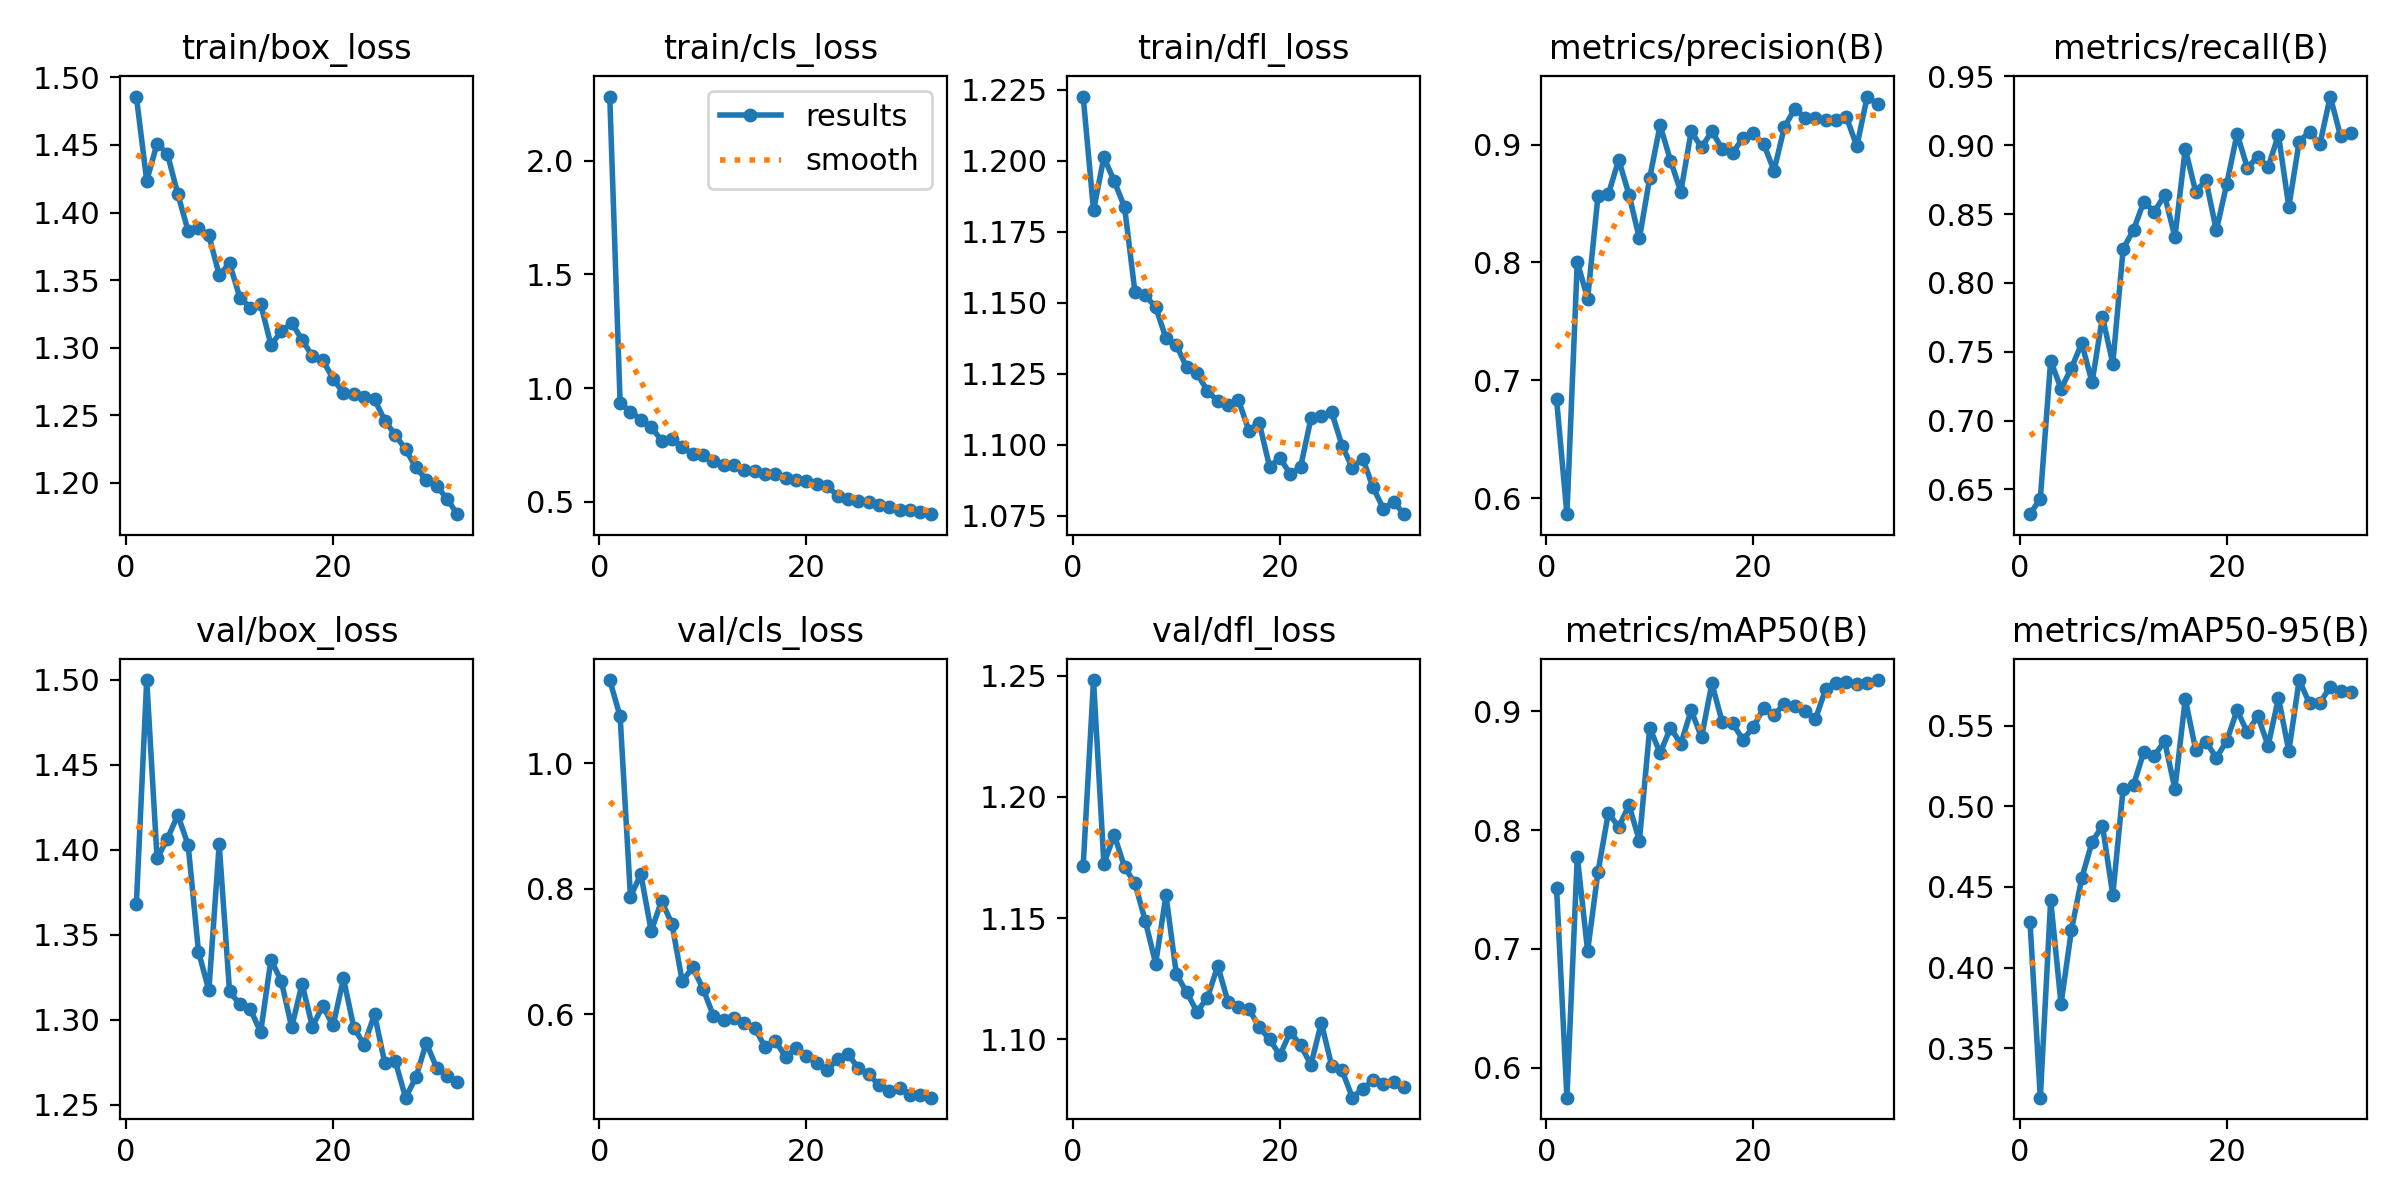

BoxPR_curve.png


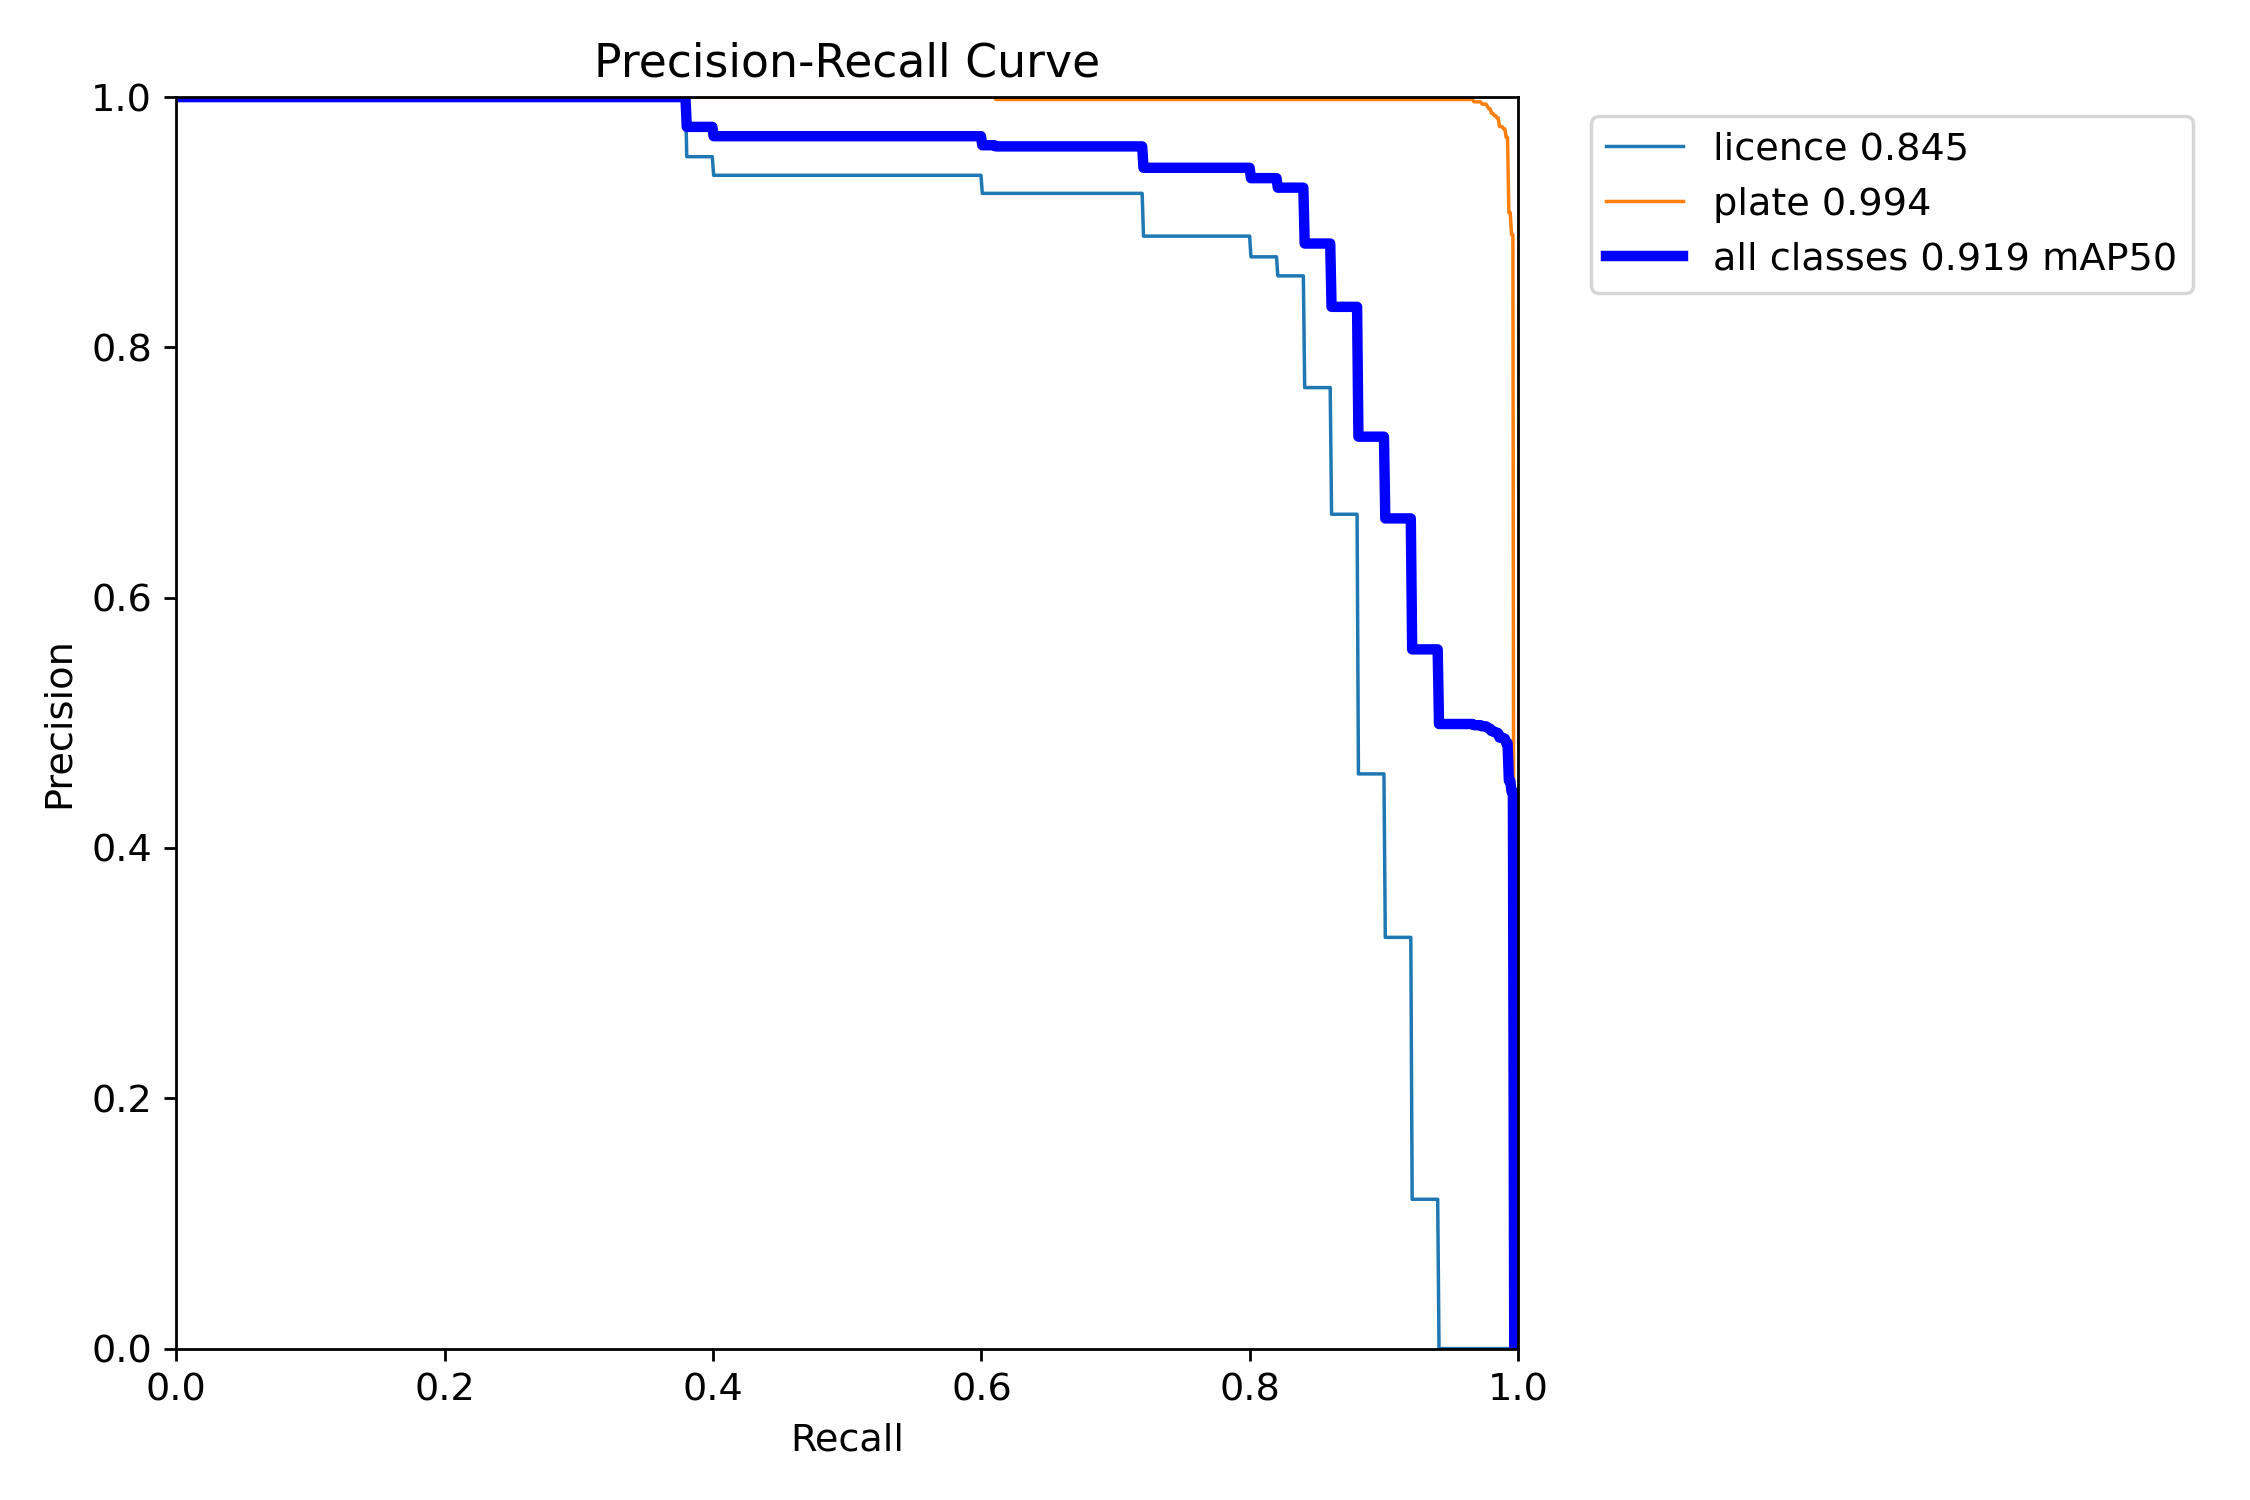

confusion_matrix_normalized.png


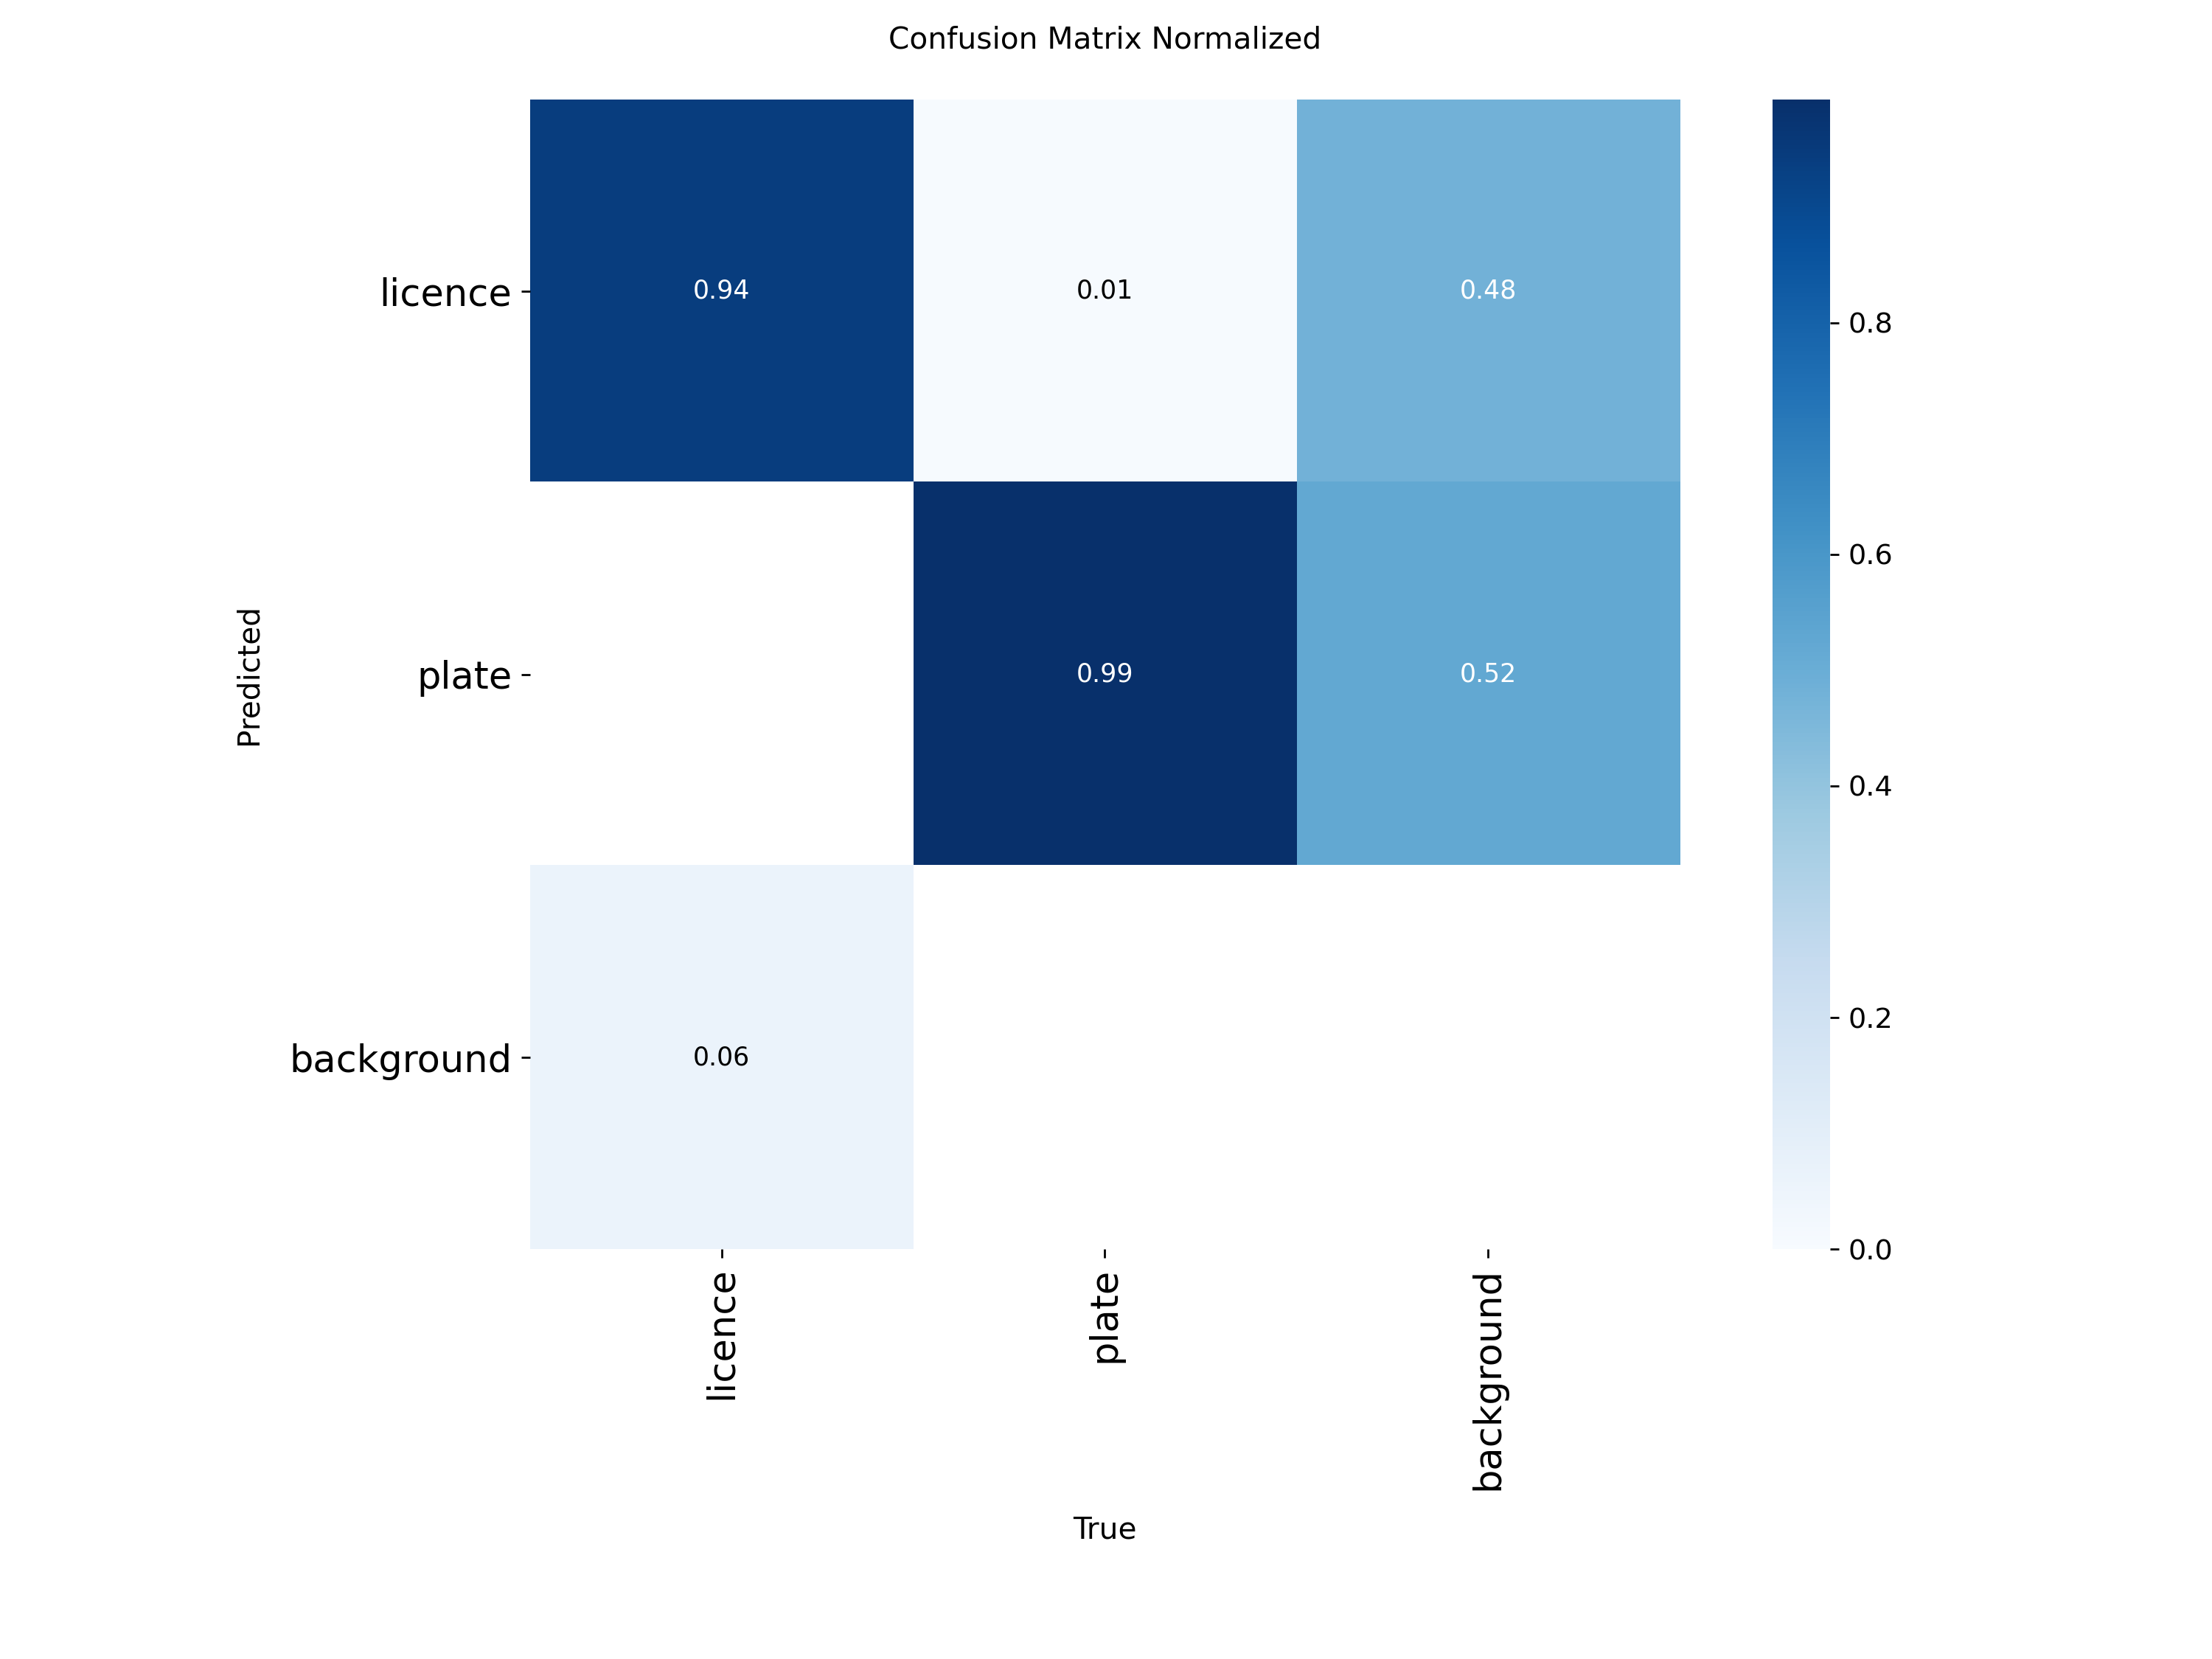

confusion_matrix.png


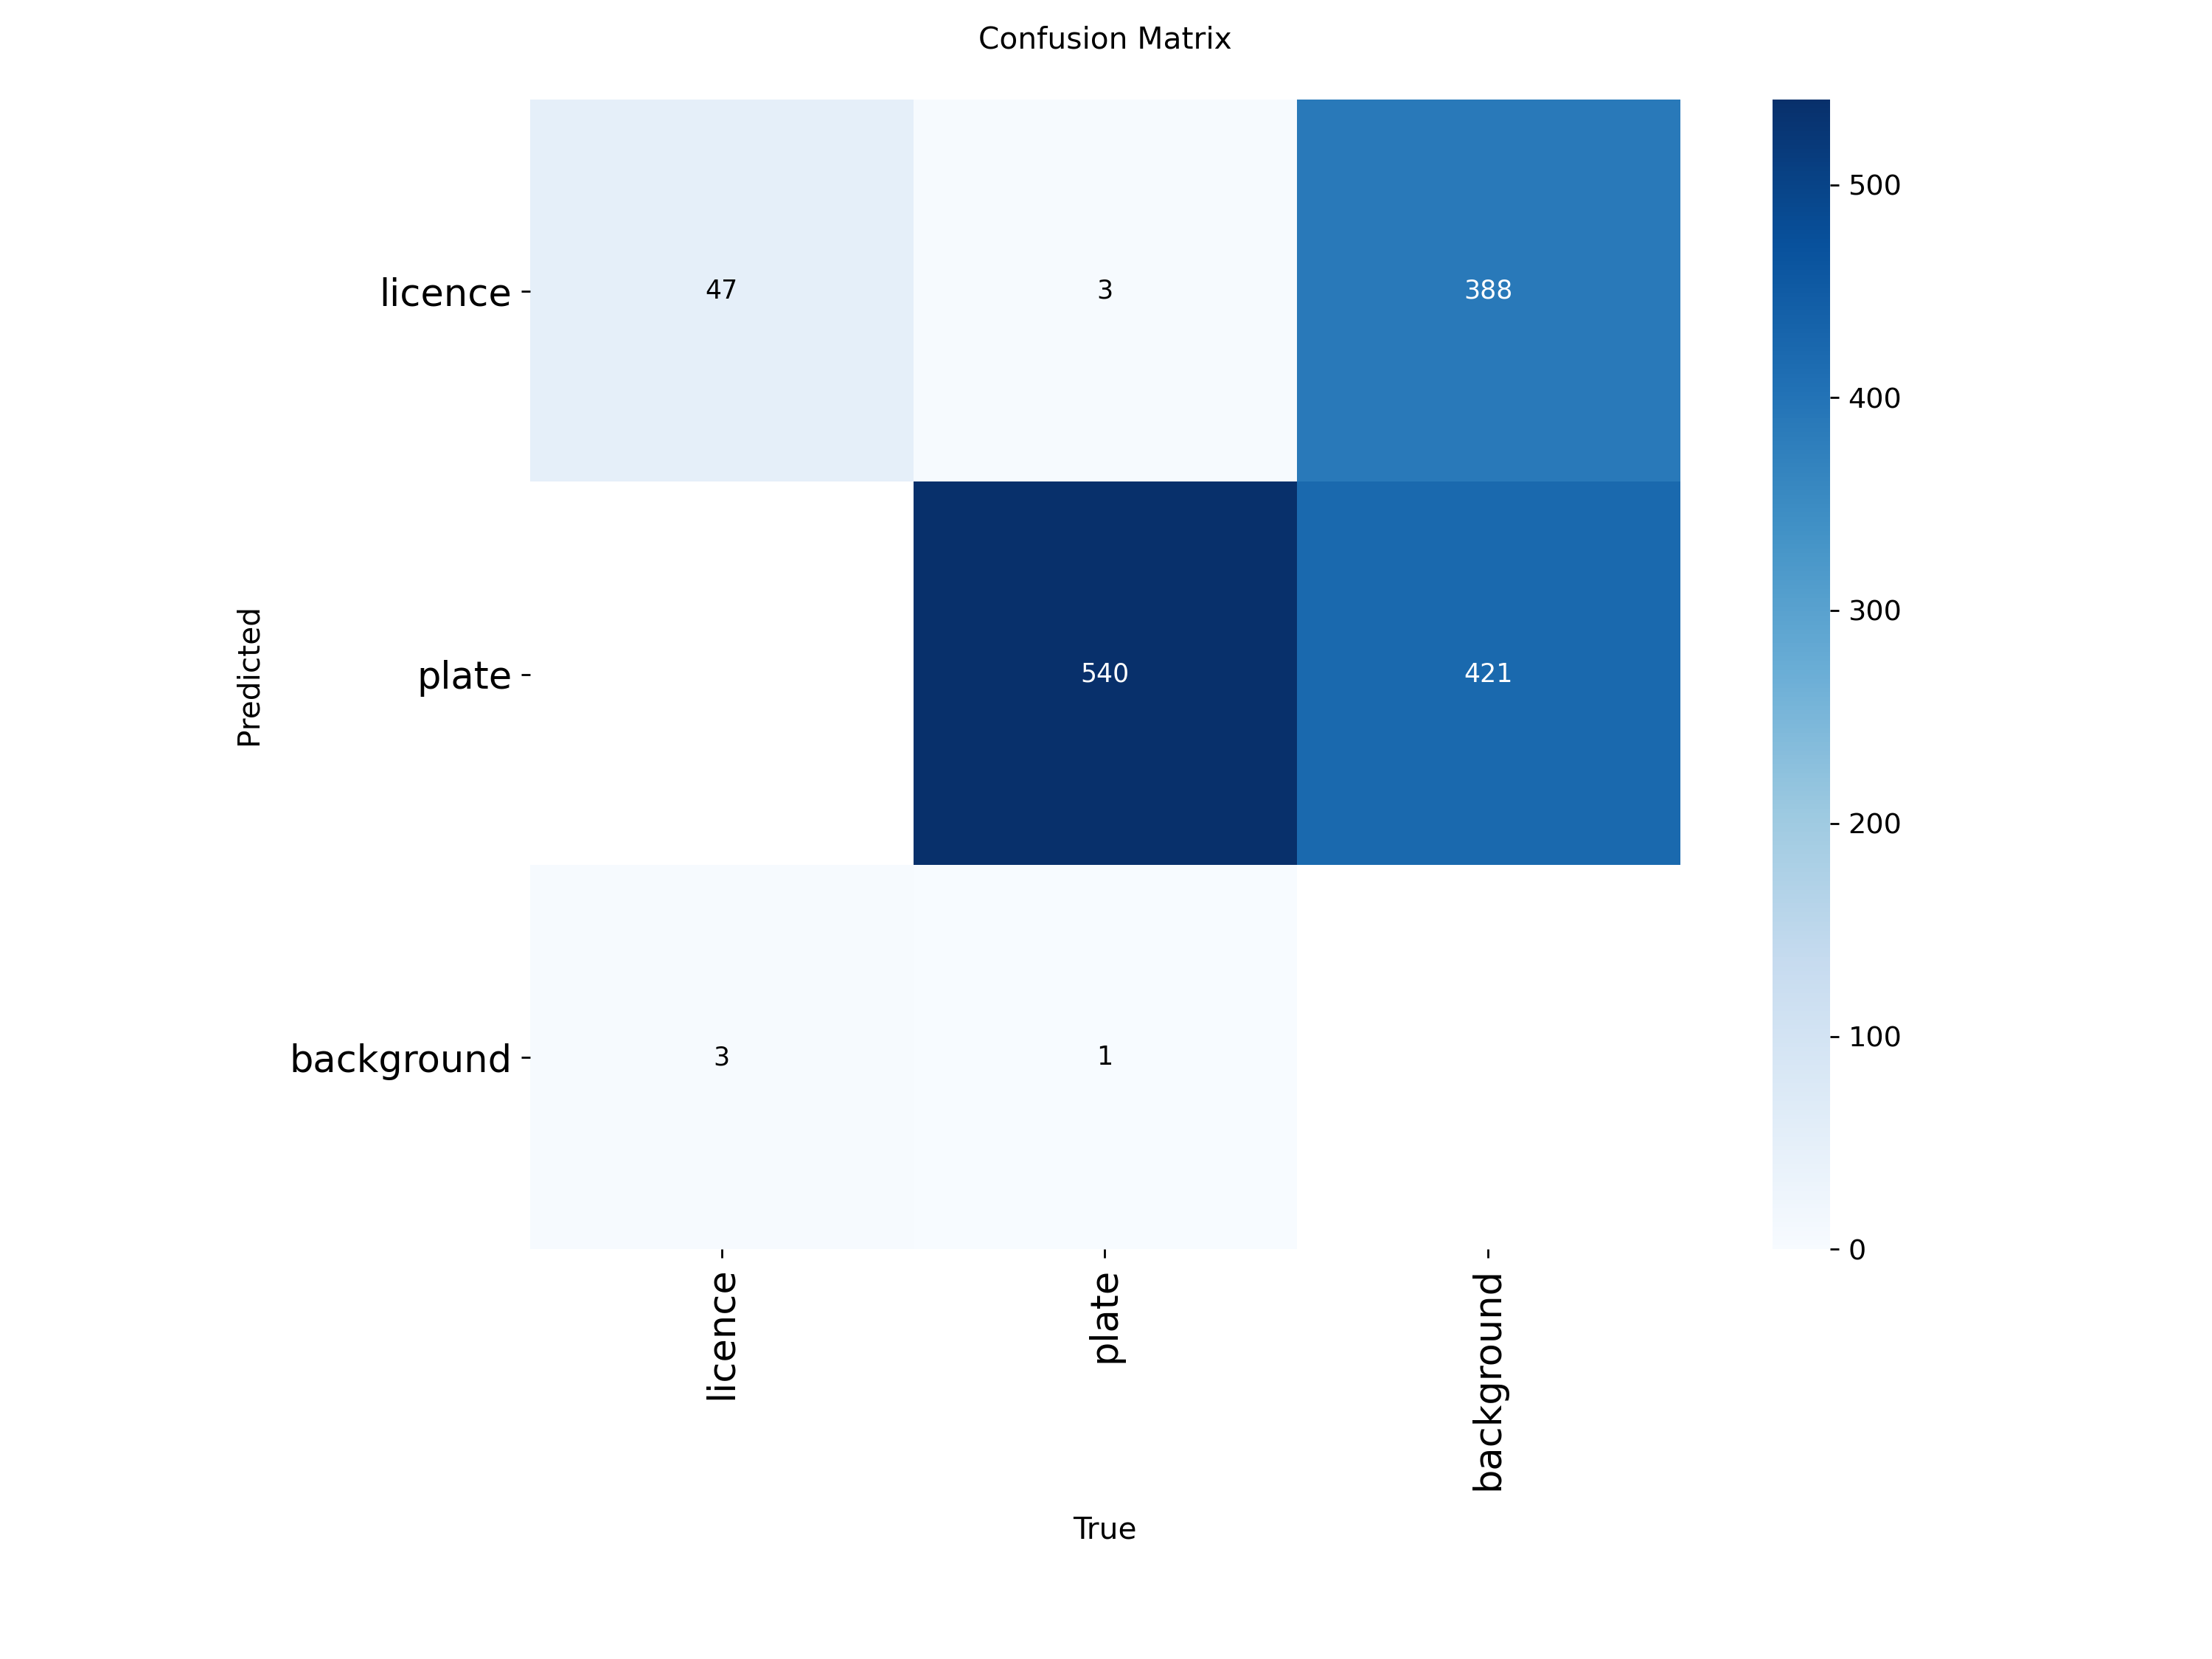

===== y26n =====
results.png


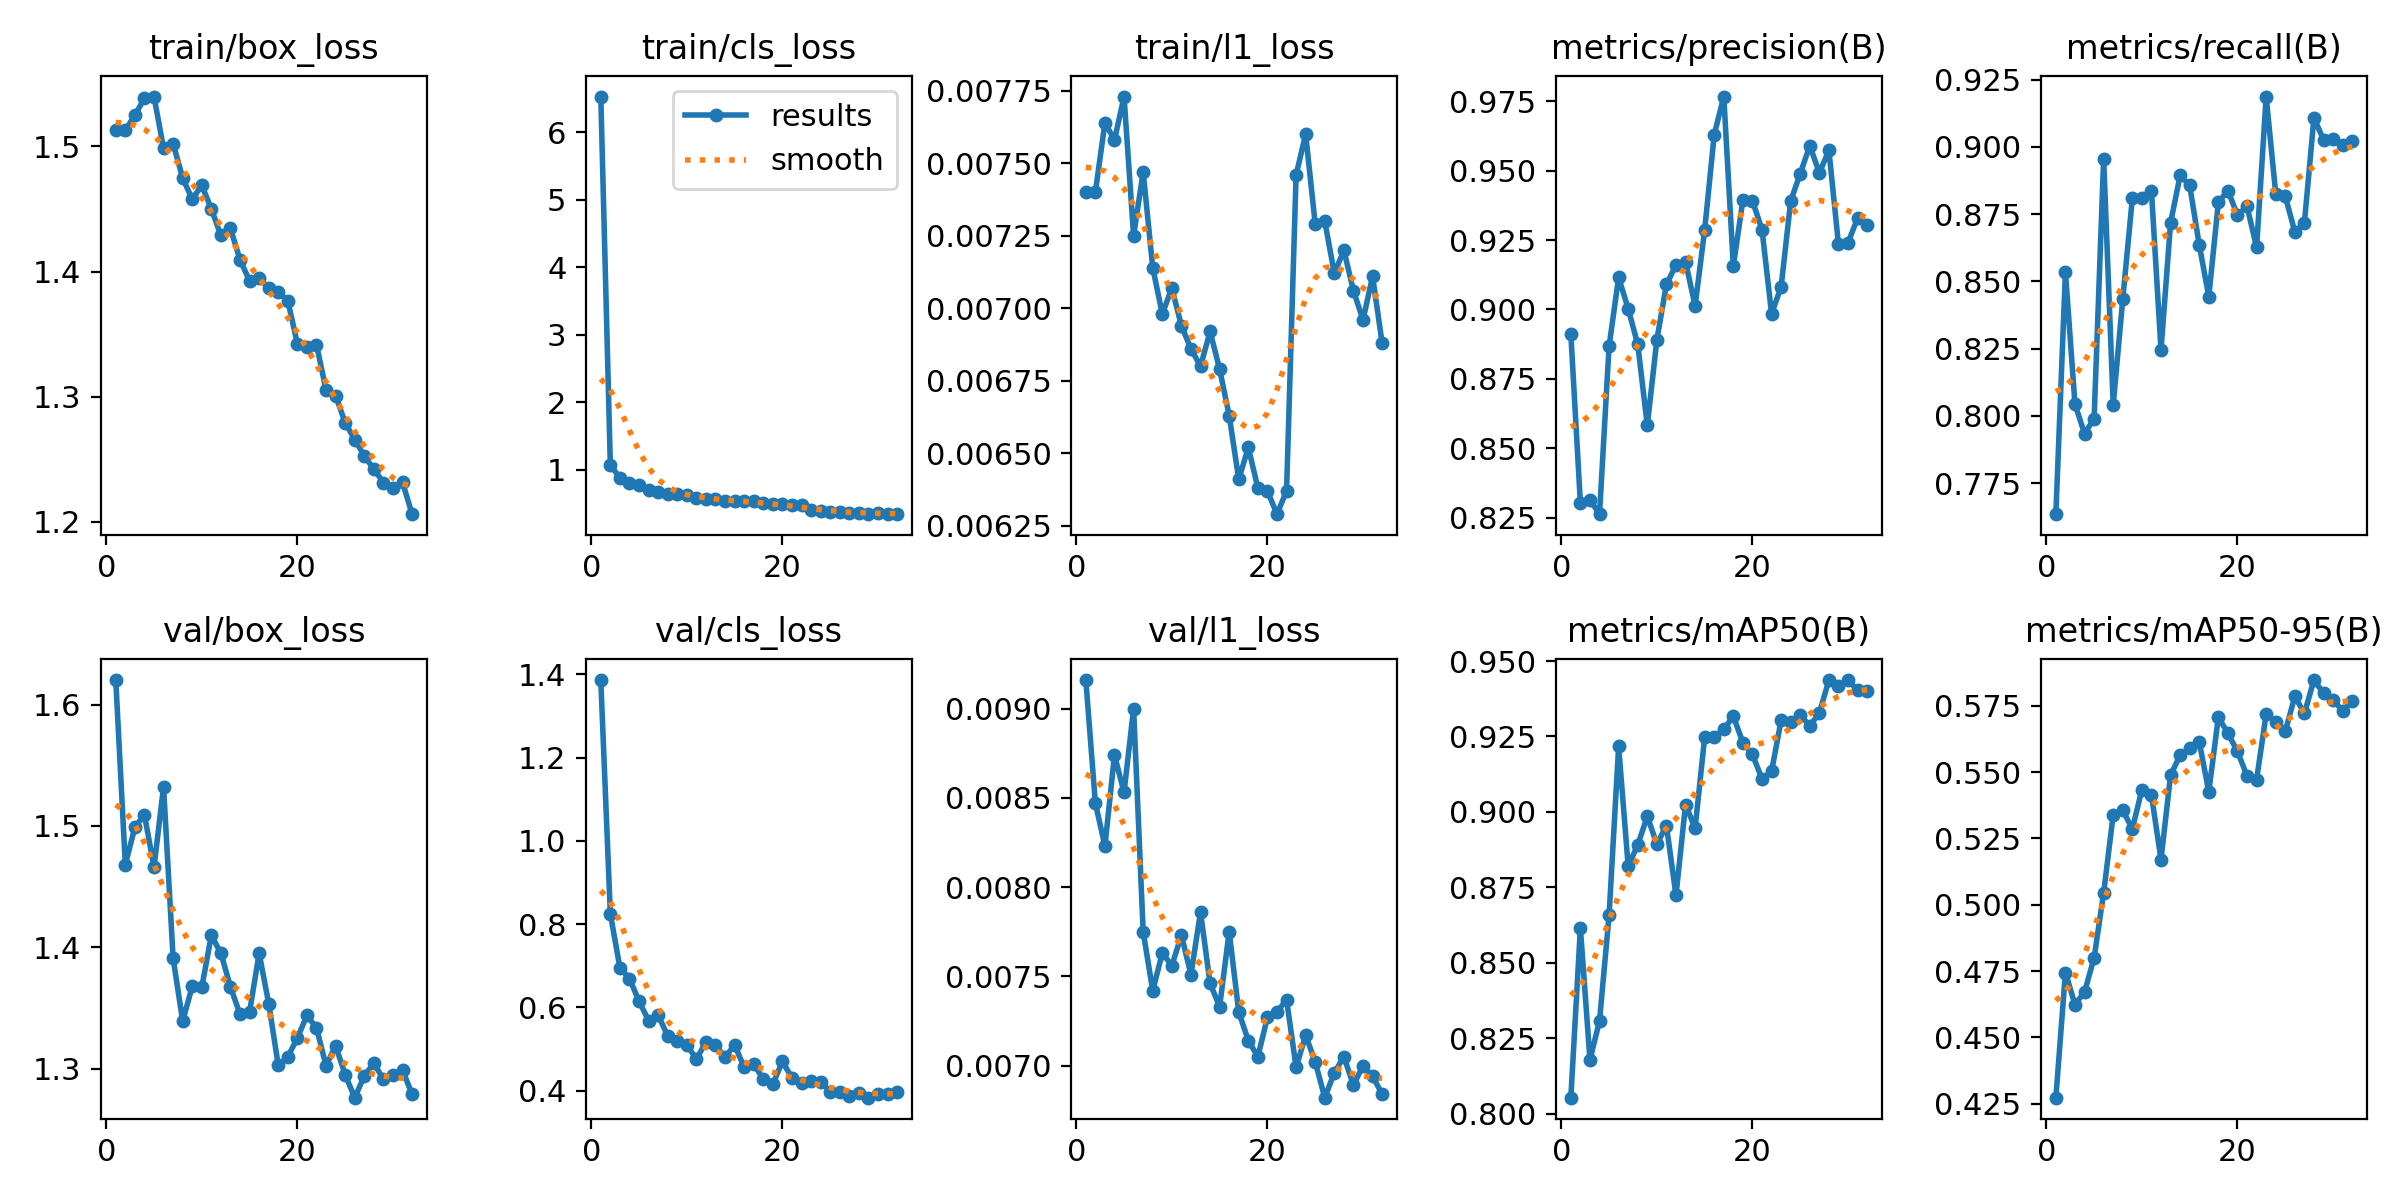

BoxPR_curve.png


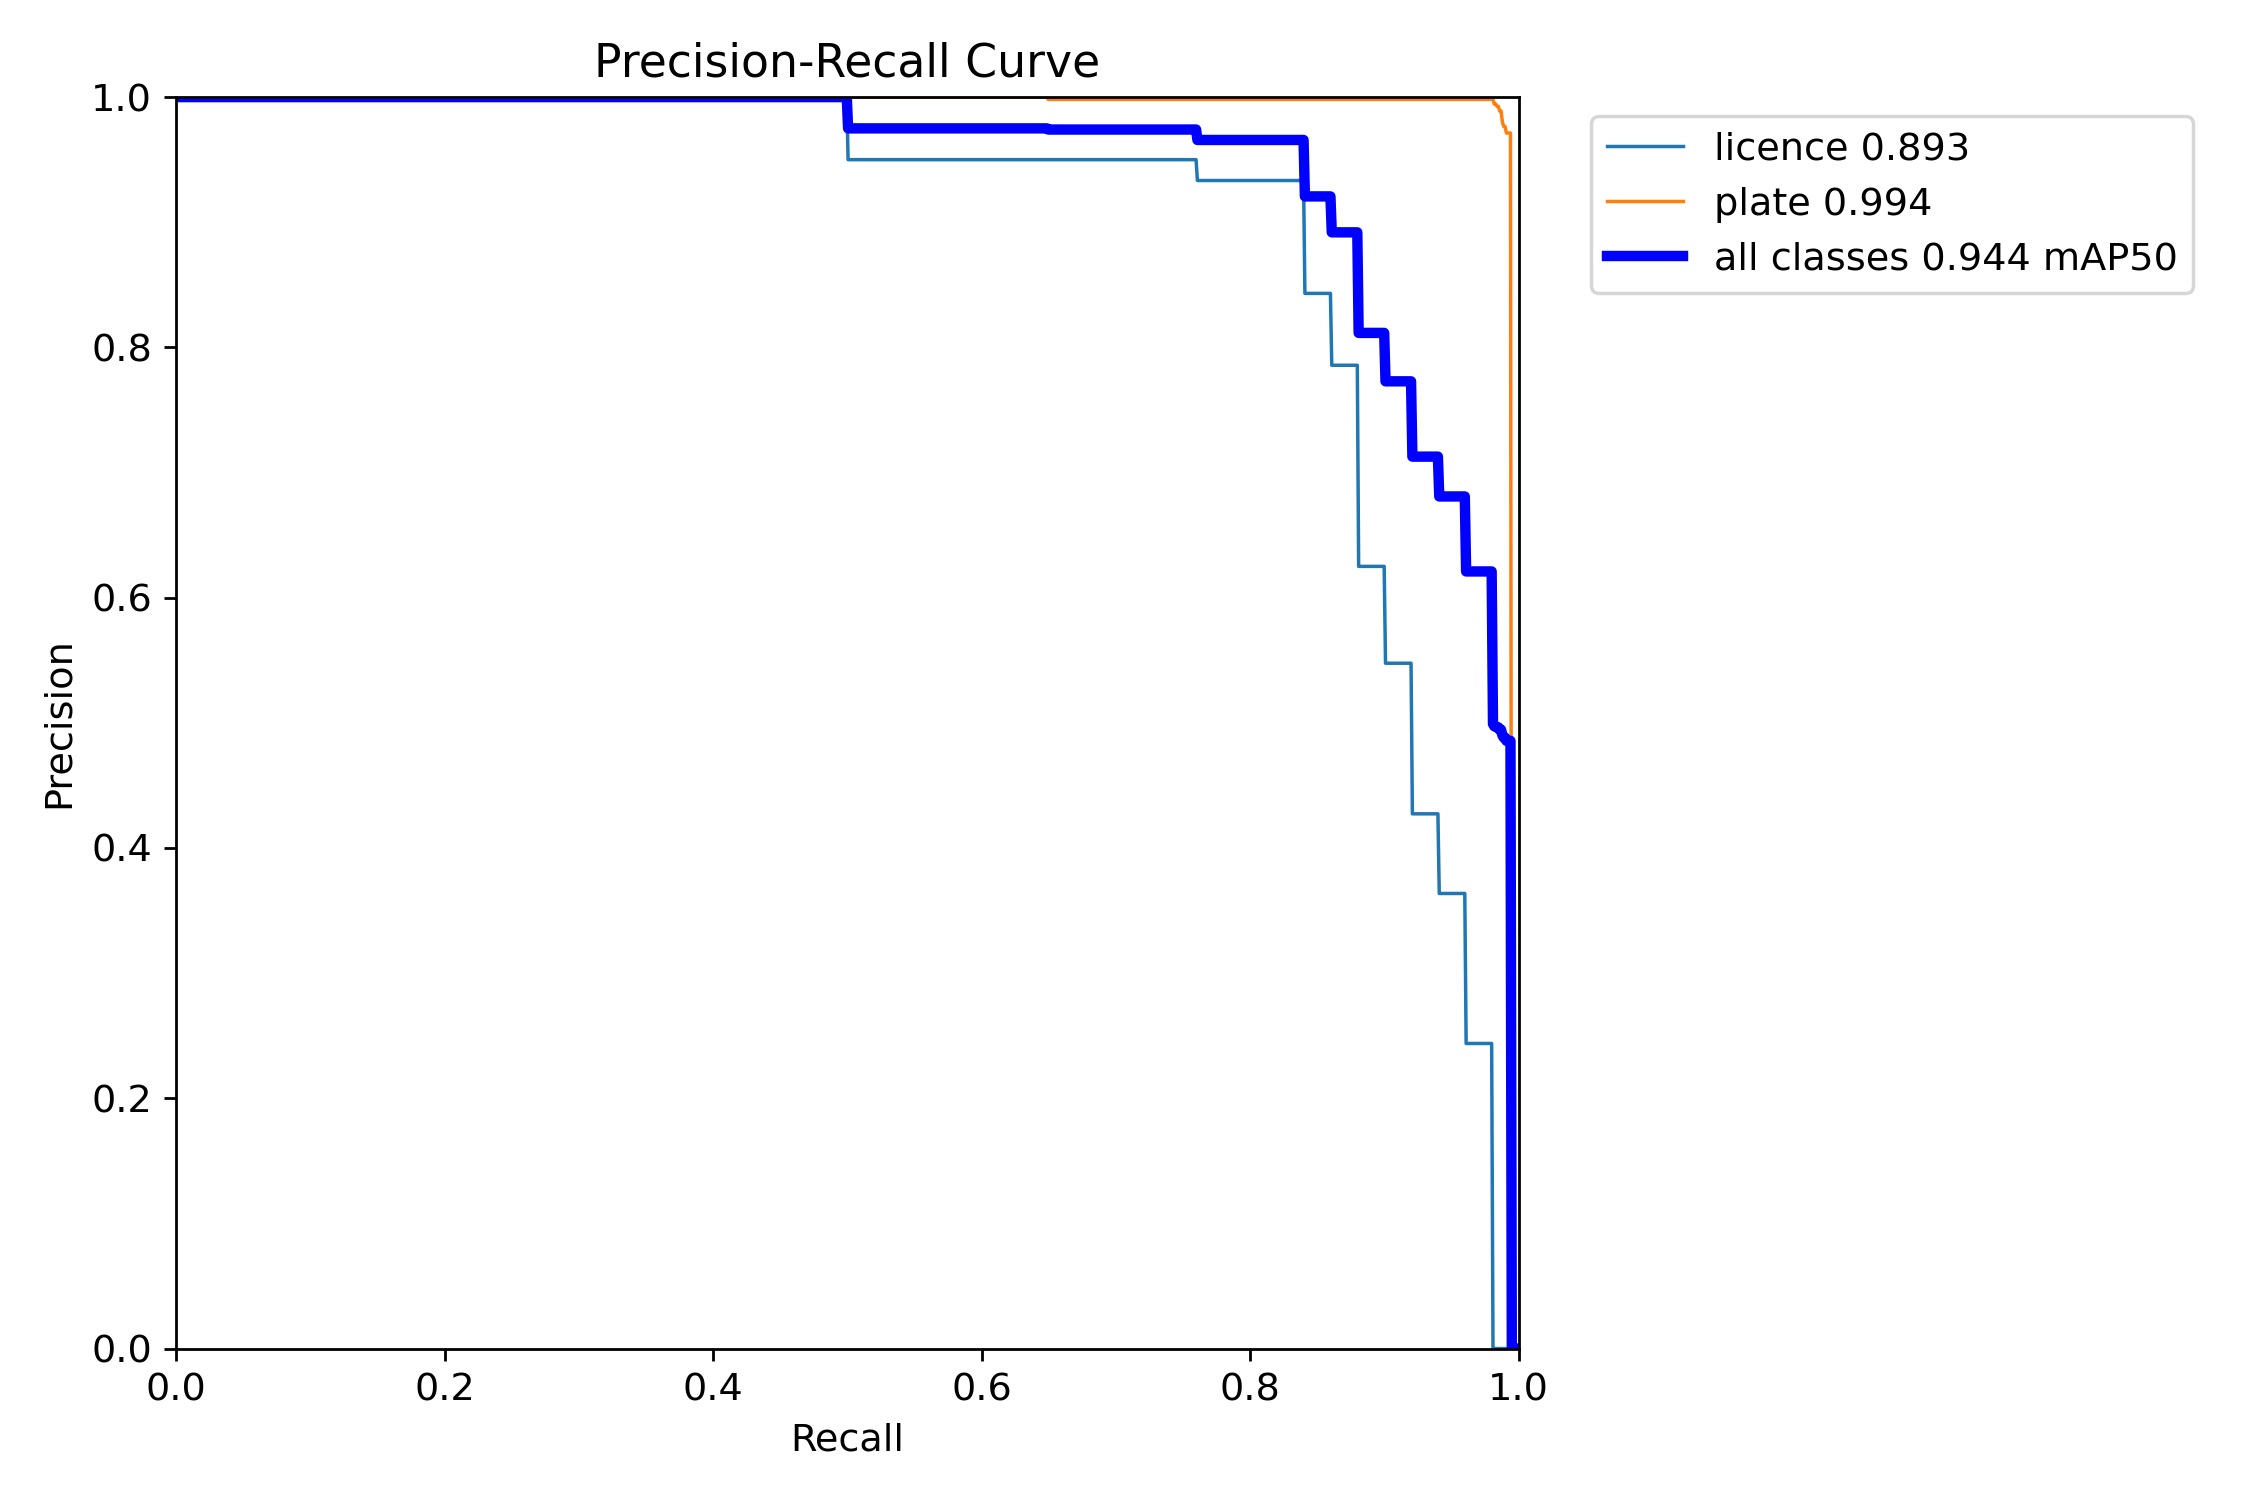

confusion_matrix_normalized.png


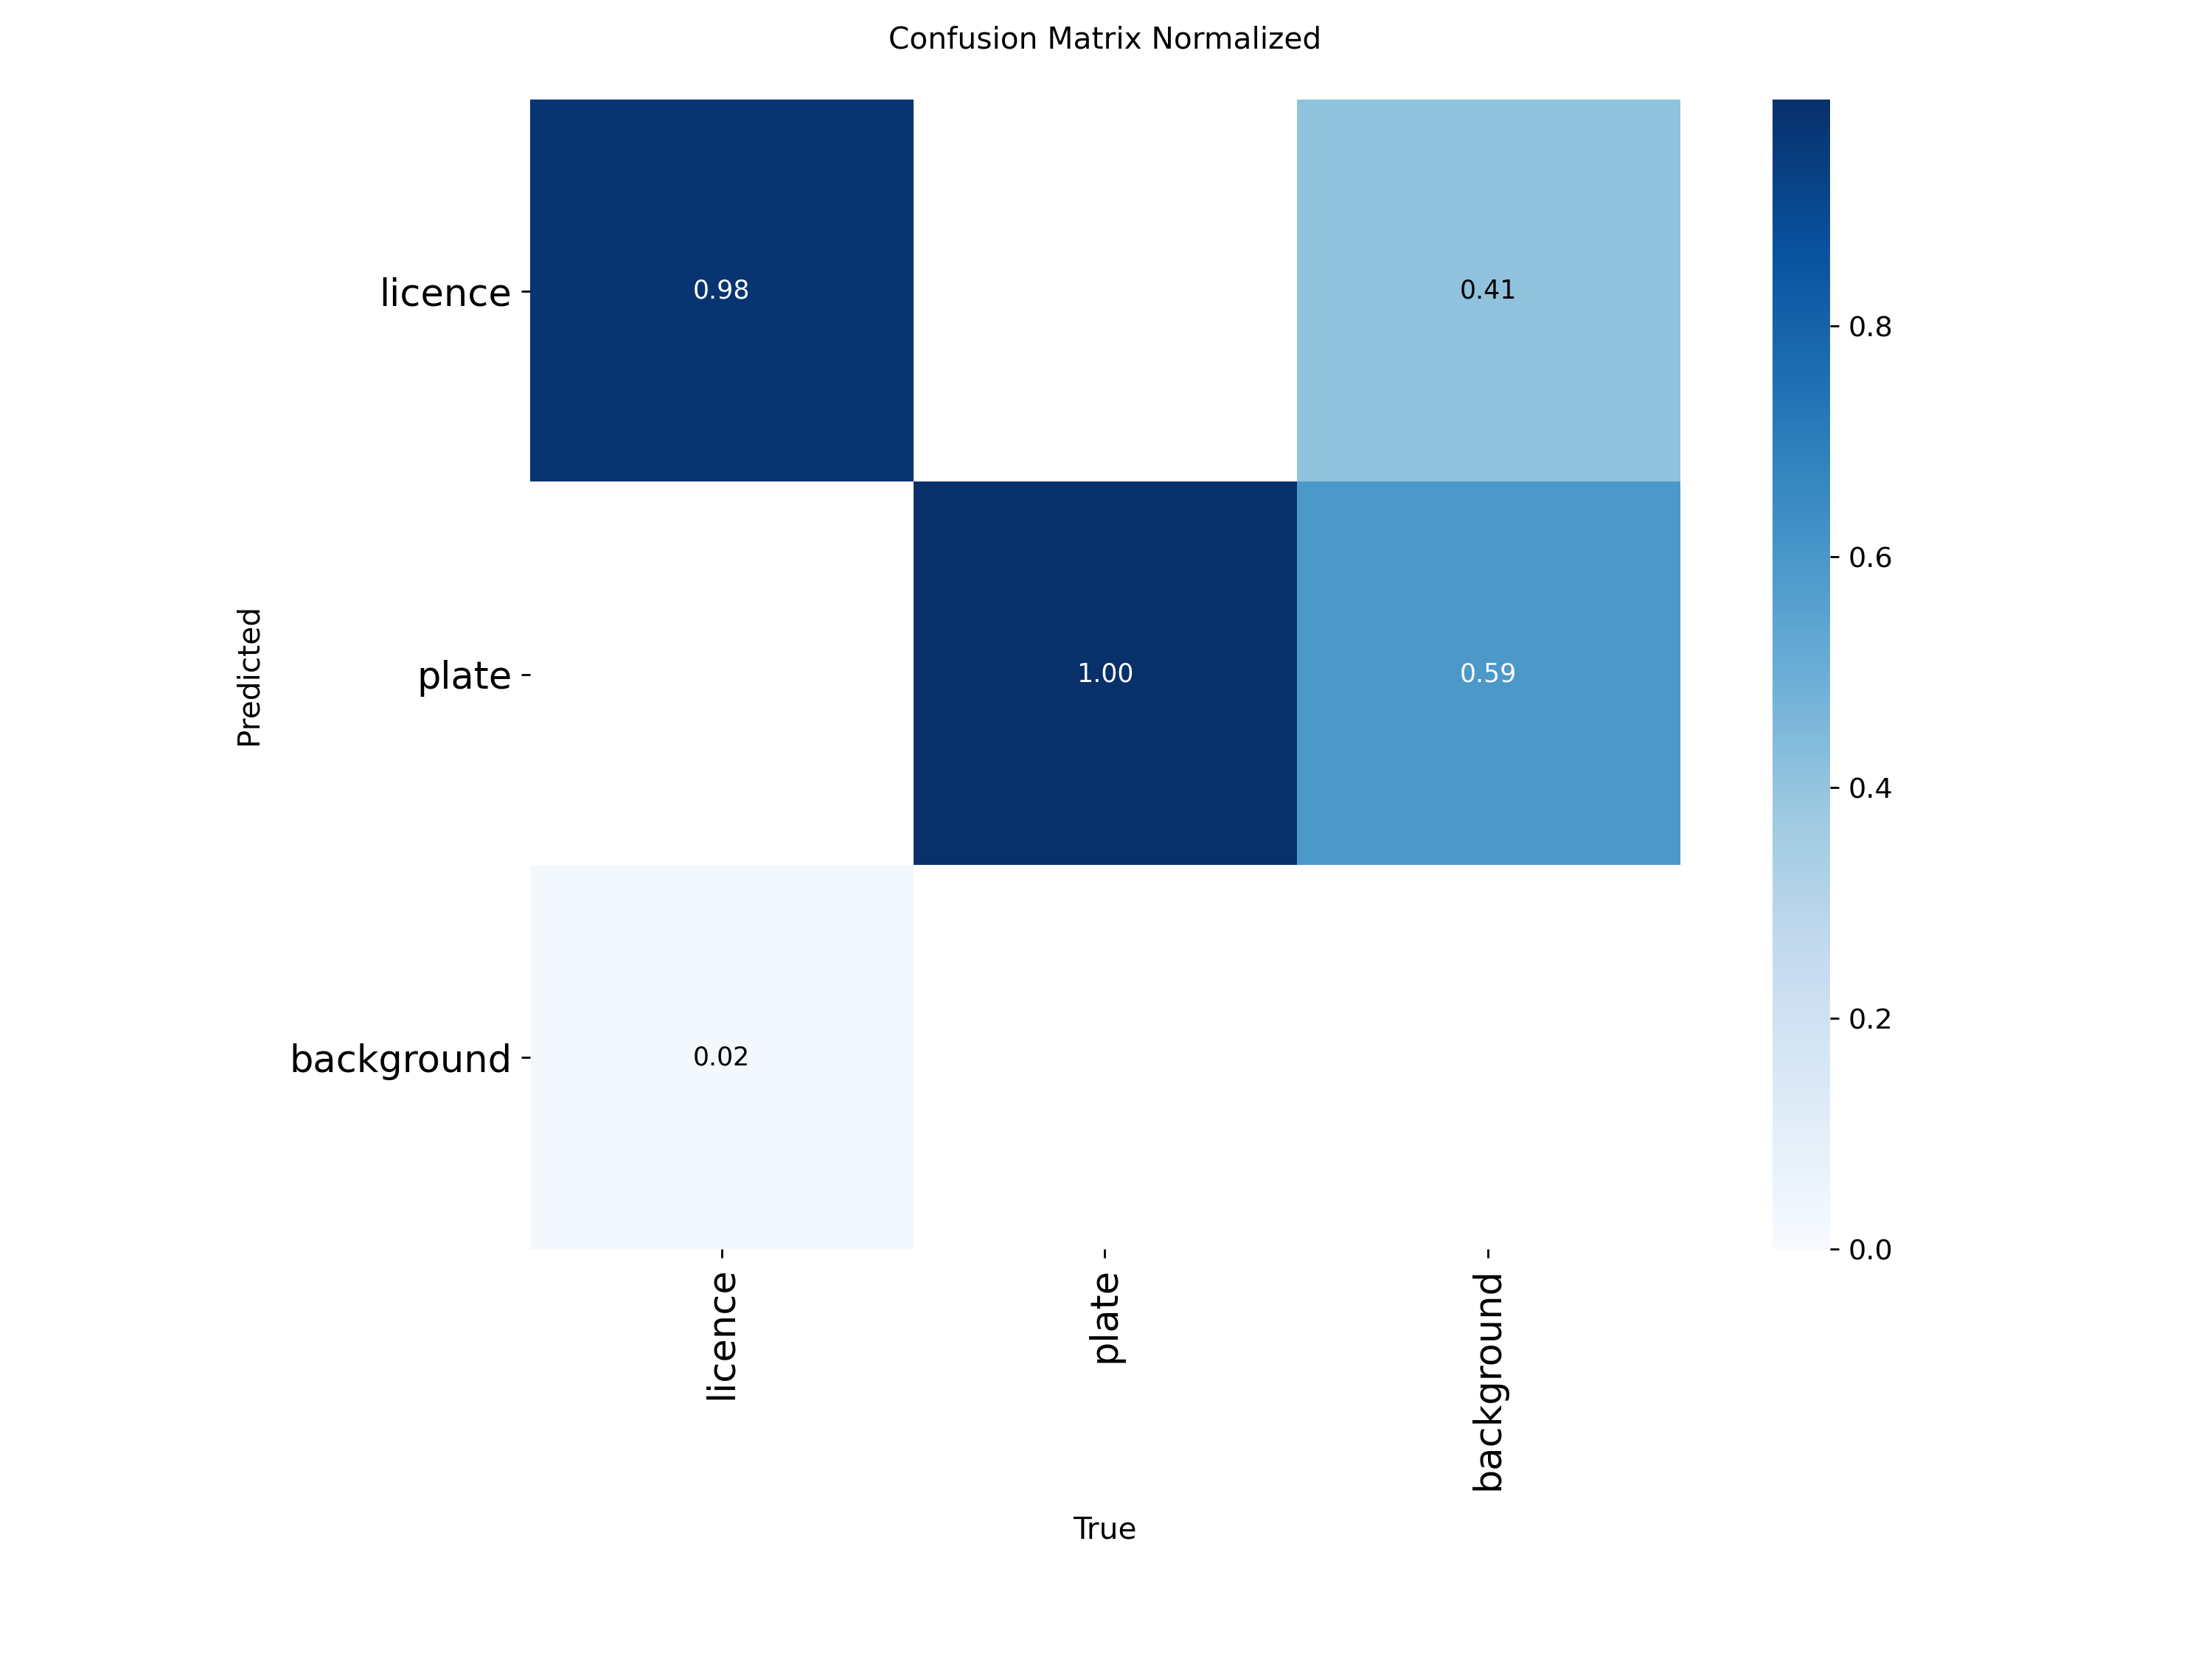

confusion_matrix.png


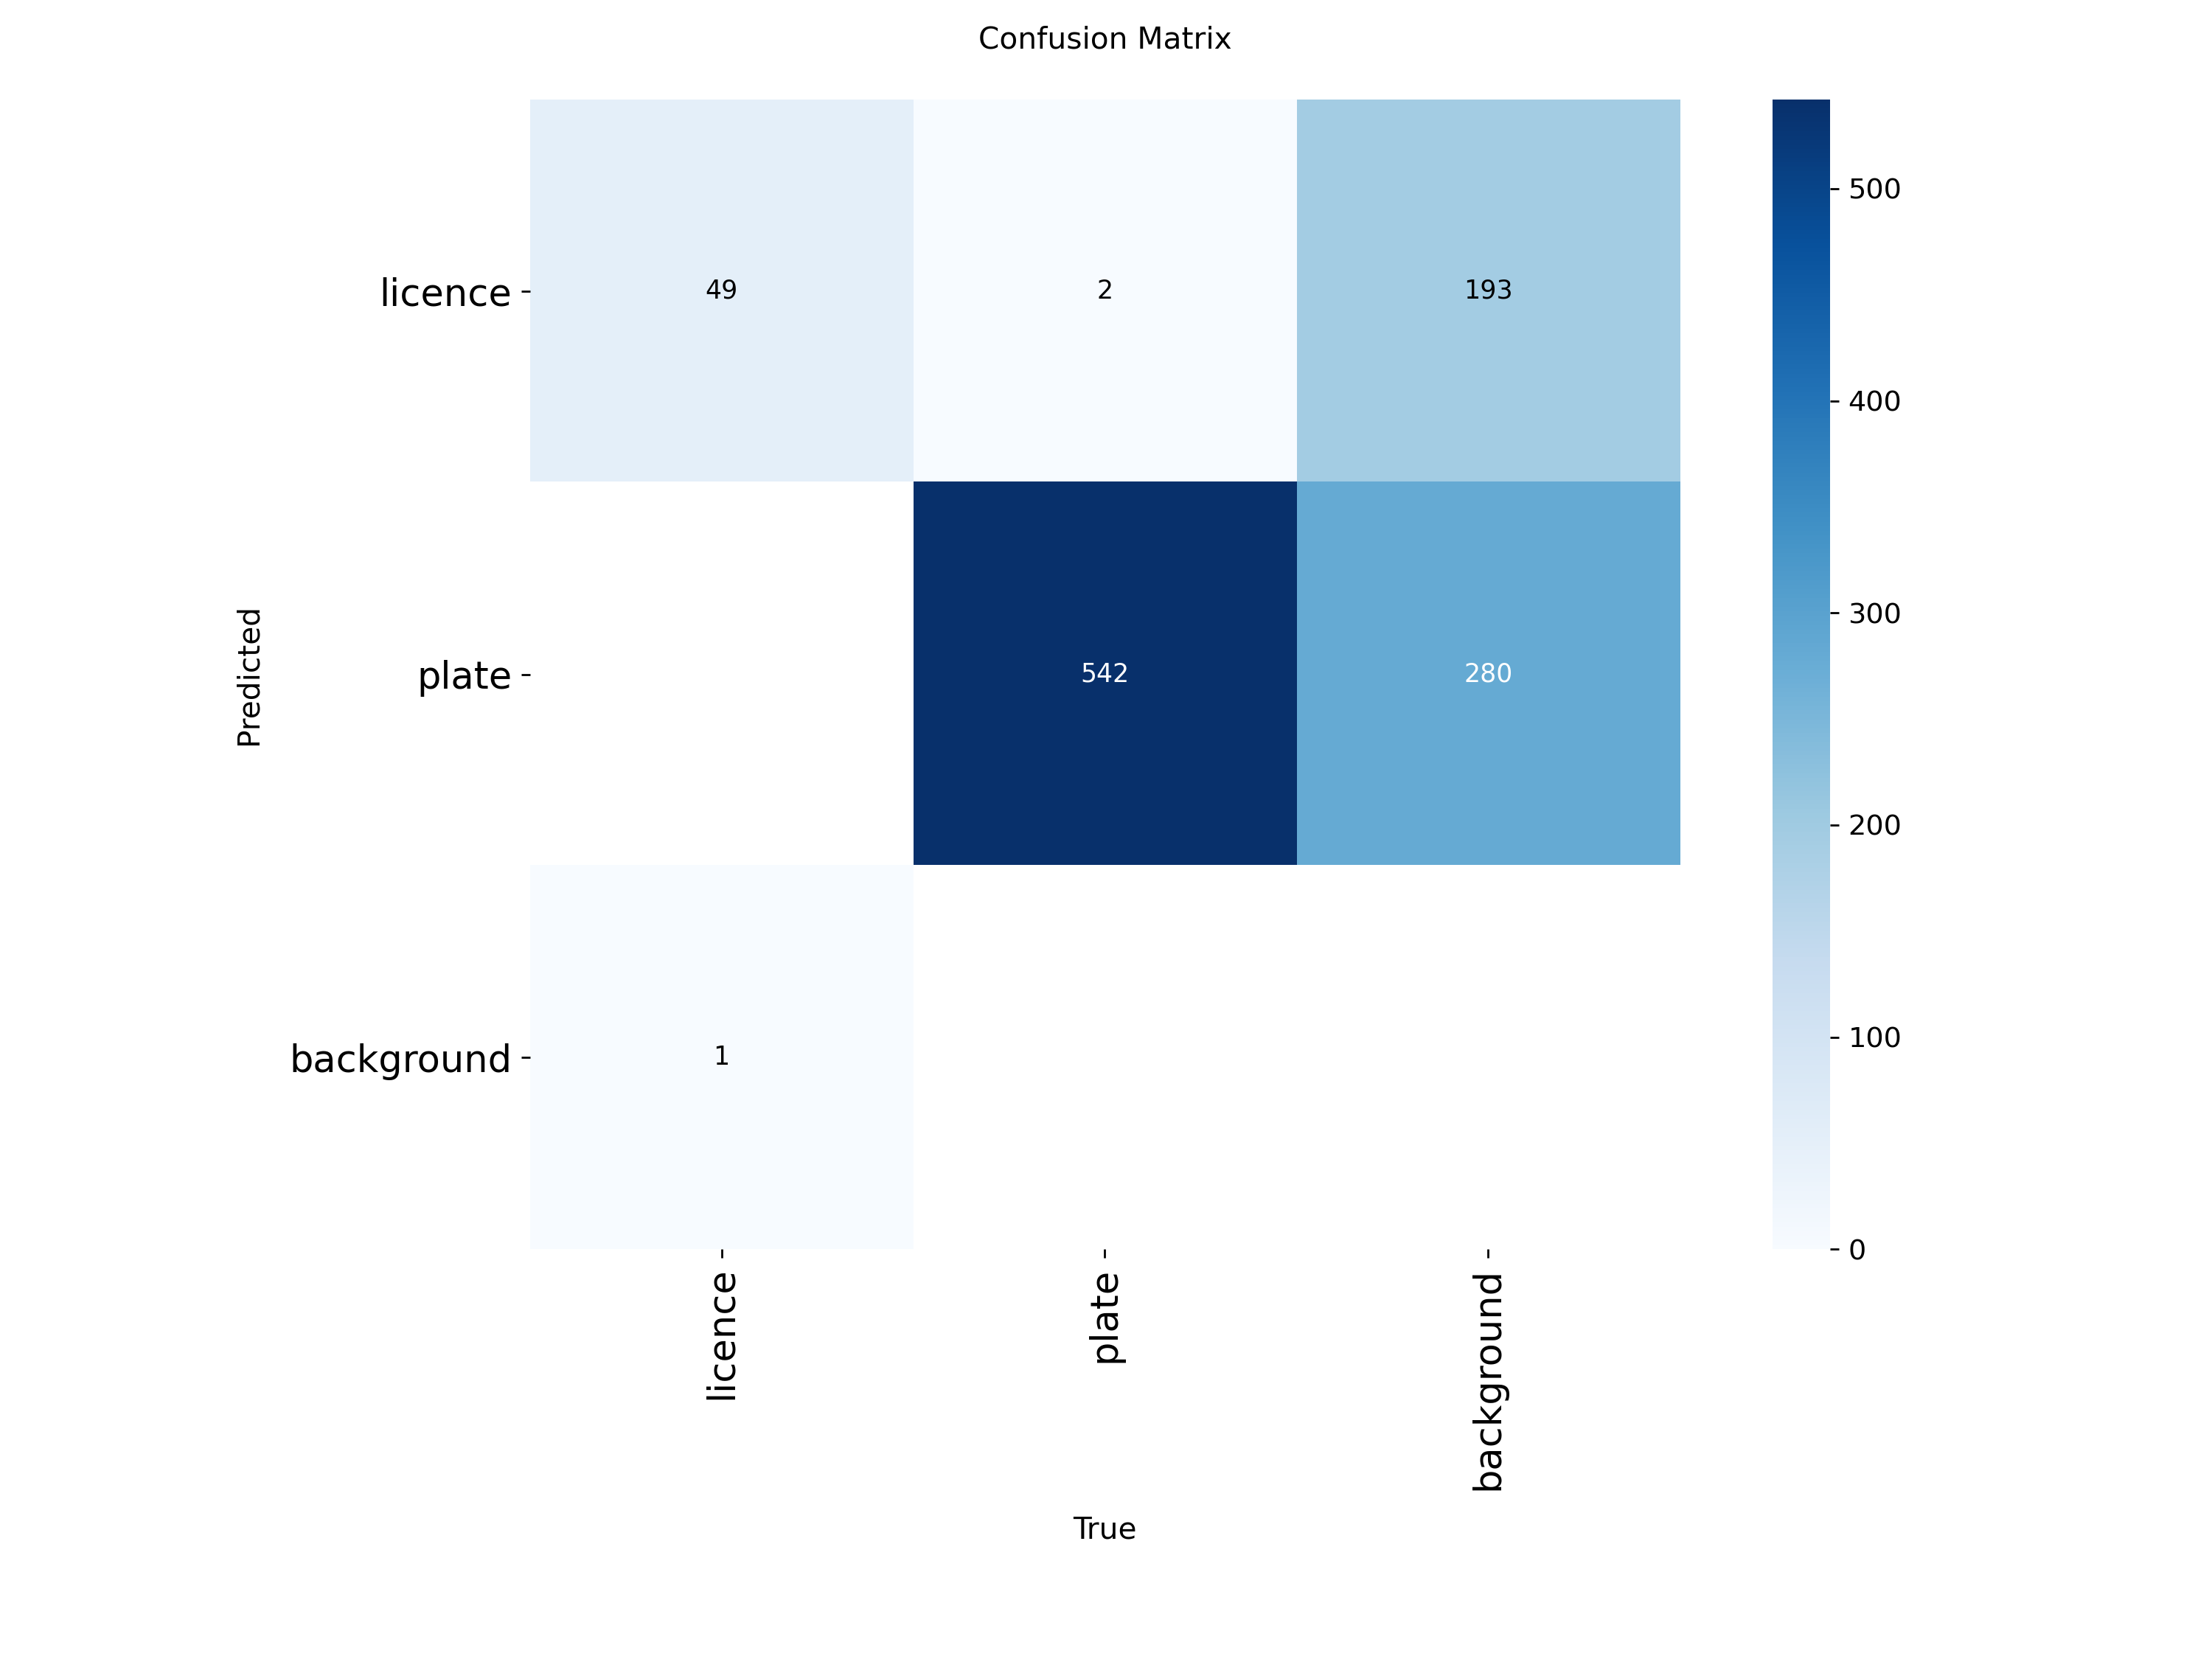

In [21]:
from IPython.display import Image, display
for run in ['v8n', 'y26n']:
    print(f'===== {run} =====')
    for f in ['results.png', 'BoxPR_curve.png', 'PR_curve.png', 'confusion_matrix_normalized.png', 'confusion_matrix.png']:
        p = f'{OUT}/{run}/{f}'
        if os.path.exists(p): print(f); display(Image(p, width=900))

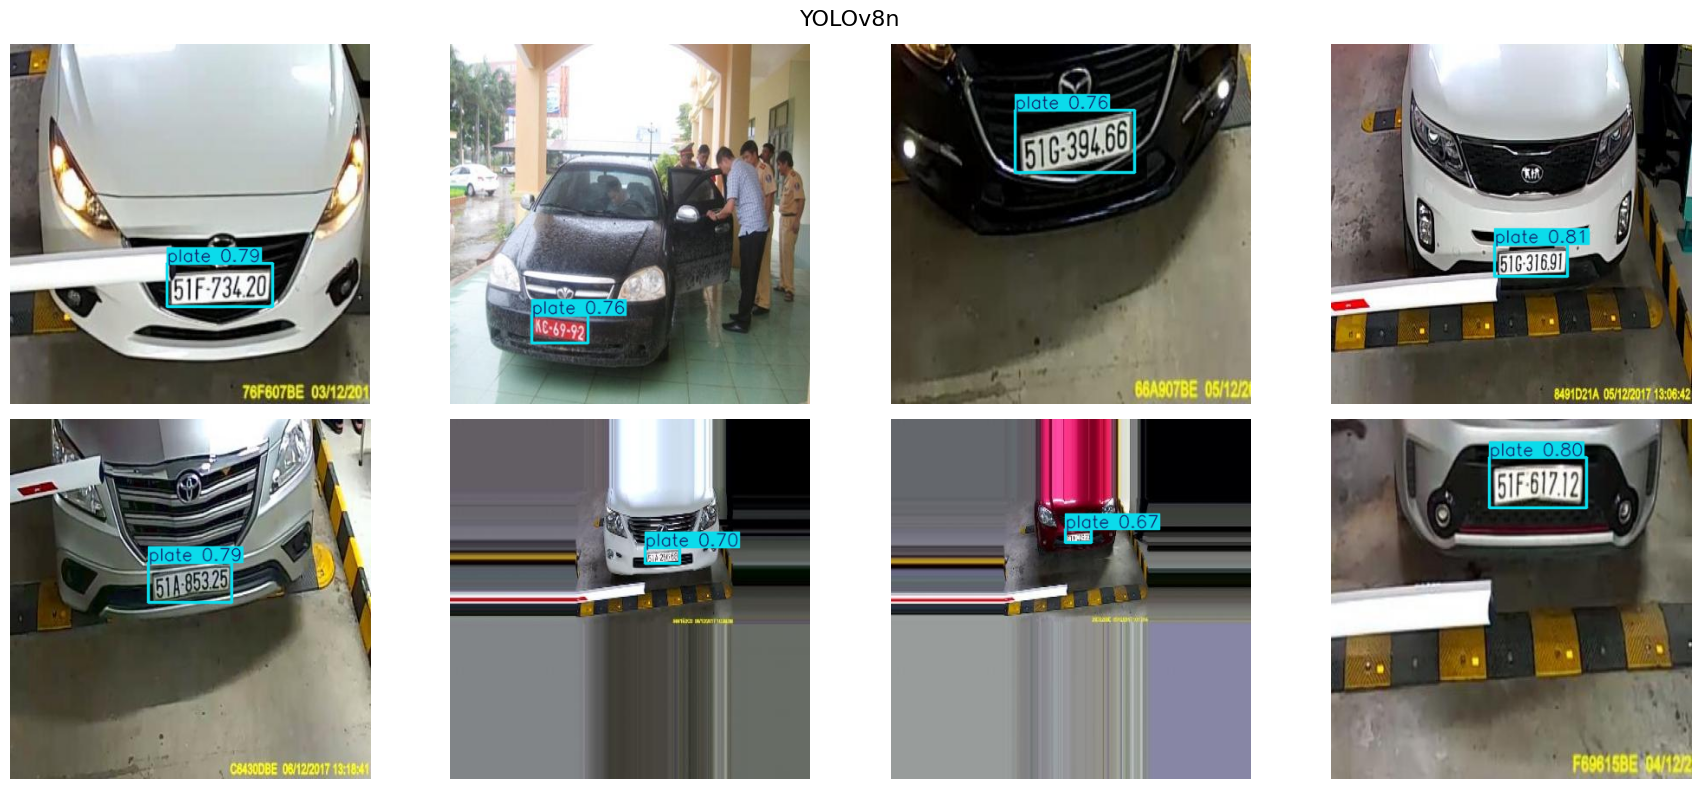

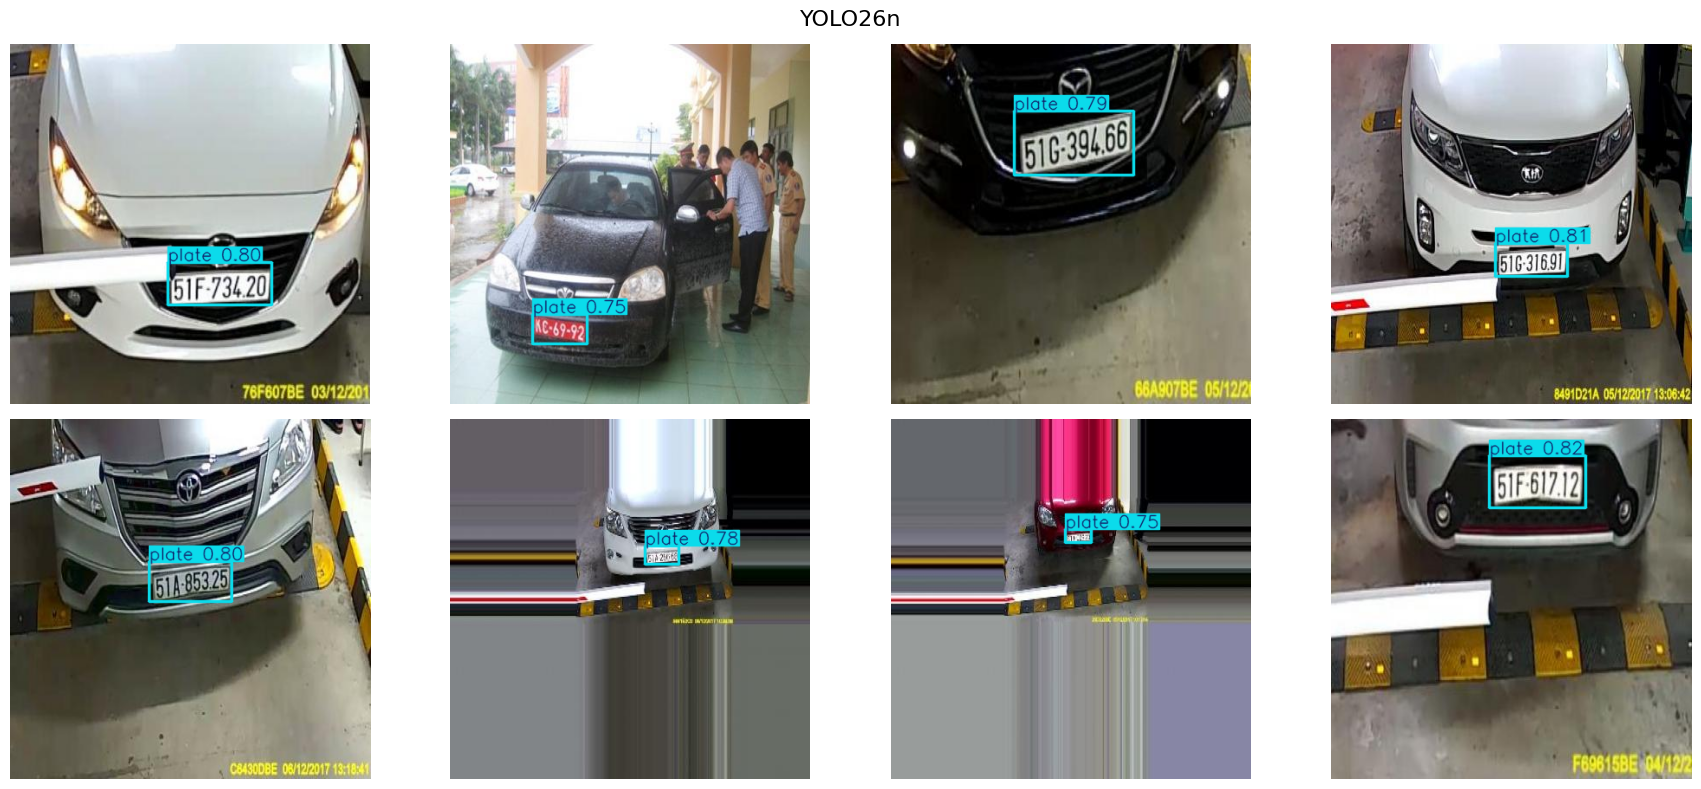

In [22]:
import random, cv2, matplotlib.pyplot as plt
random.seed(0)
sample = random.sample(sorted(glob.glob(f'{root}/test/images/*')), 8)
for mname, w in MODELS.items():
    res = YOLO(w).predict(sample, imgsz=640, conf=0.25, verbose=False)
    fig, axs = plt.subplots(2, 4, figsize=(18, 8)); fig.suptitle(mname, fontsize=16)
    for ax, r in zip(axs.ravel(), res):
        ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); ax.axis('off')
    plt.tight_layout(); plt.savefig(f'{OUT}/preds_{mname}.png', dpi=120); plt.show()

In [23]:
test = acc[acc.split == 'test'].drop(columns='split')
summary = test.merge(cxdf, on='model').merge(pardf[['model', 'onnx_MB', 'mAP50_onnx']], on='model') \
              .merge(bdf[['model', 'mean_ms', 'fps']], on='model')
summary.to_csv(f'{OUT}/summary.csv', index=False)
print(summary.round(4).T.to_string())
print('\nAll files saved in', OUT)

                      0        1
model           YOLOv8n  YOLO26n
P                0.8689   0.8294
R                0.8274   0.8519
mAP50            0.8697   0.8373
mAP50_95         0.5148   0.5148
gpu_infer_ms     5.4363   5.6822
gpu_post_ms      2.8495   2.5655
mAP50_licence    0.7443   0.6796
mAP50_plate       0.995    0.995
layers              226      455
params_M         3.1382   2.5344
GFLOPs           8.7503     6.03
pt_MB            6.5046   5.4511
onnx_MB         12.7741   9.8533
mAP50_onnx       0.8561   0.8404
mean_ms        113.6051  90.5436
fps              8.8024  11.0444

All files saved in /content/drive/MyDrive/edge_anpr/stage2


## 10. Visualisations
Training curves, PR curve and confusion matrix for each model, then sample predictions on the same 8 test images so the two models are compared on identical inputs.


===== V8N Training Curves & Performance Figures =====

--- Showing: results.png ---


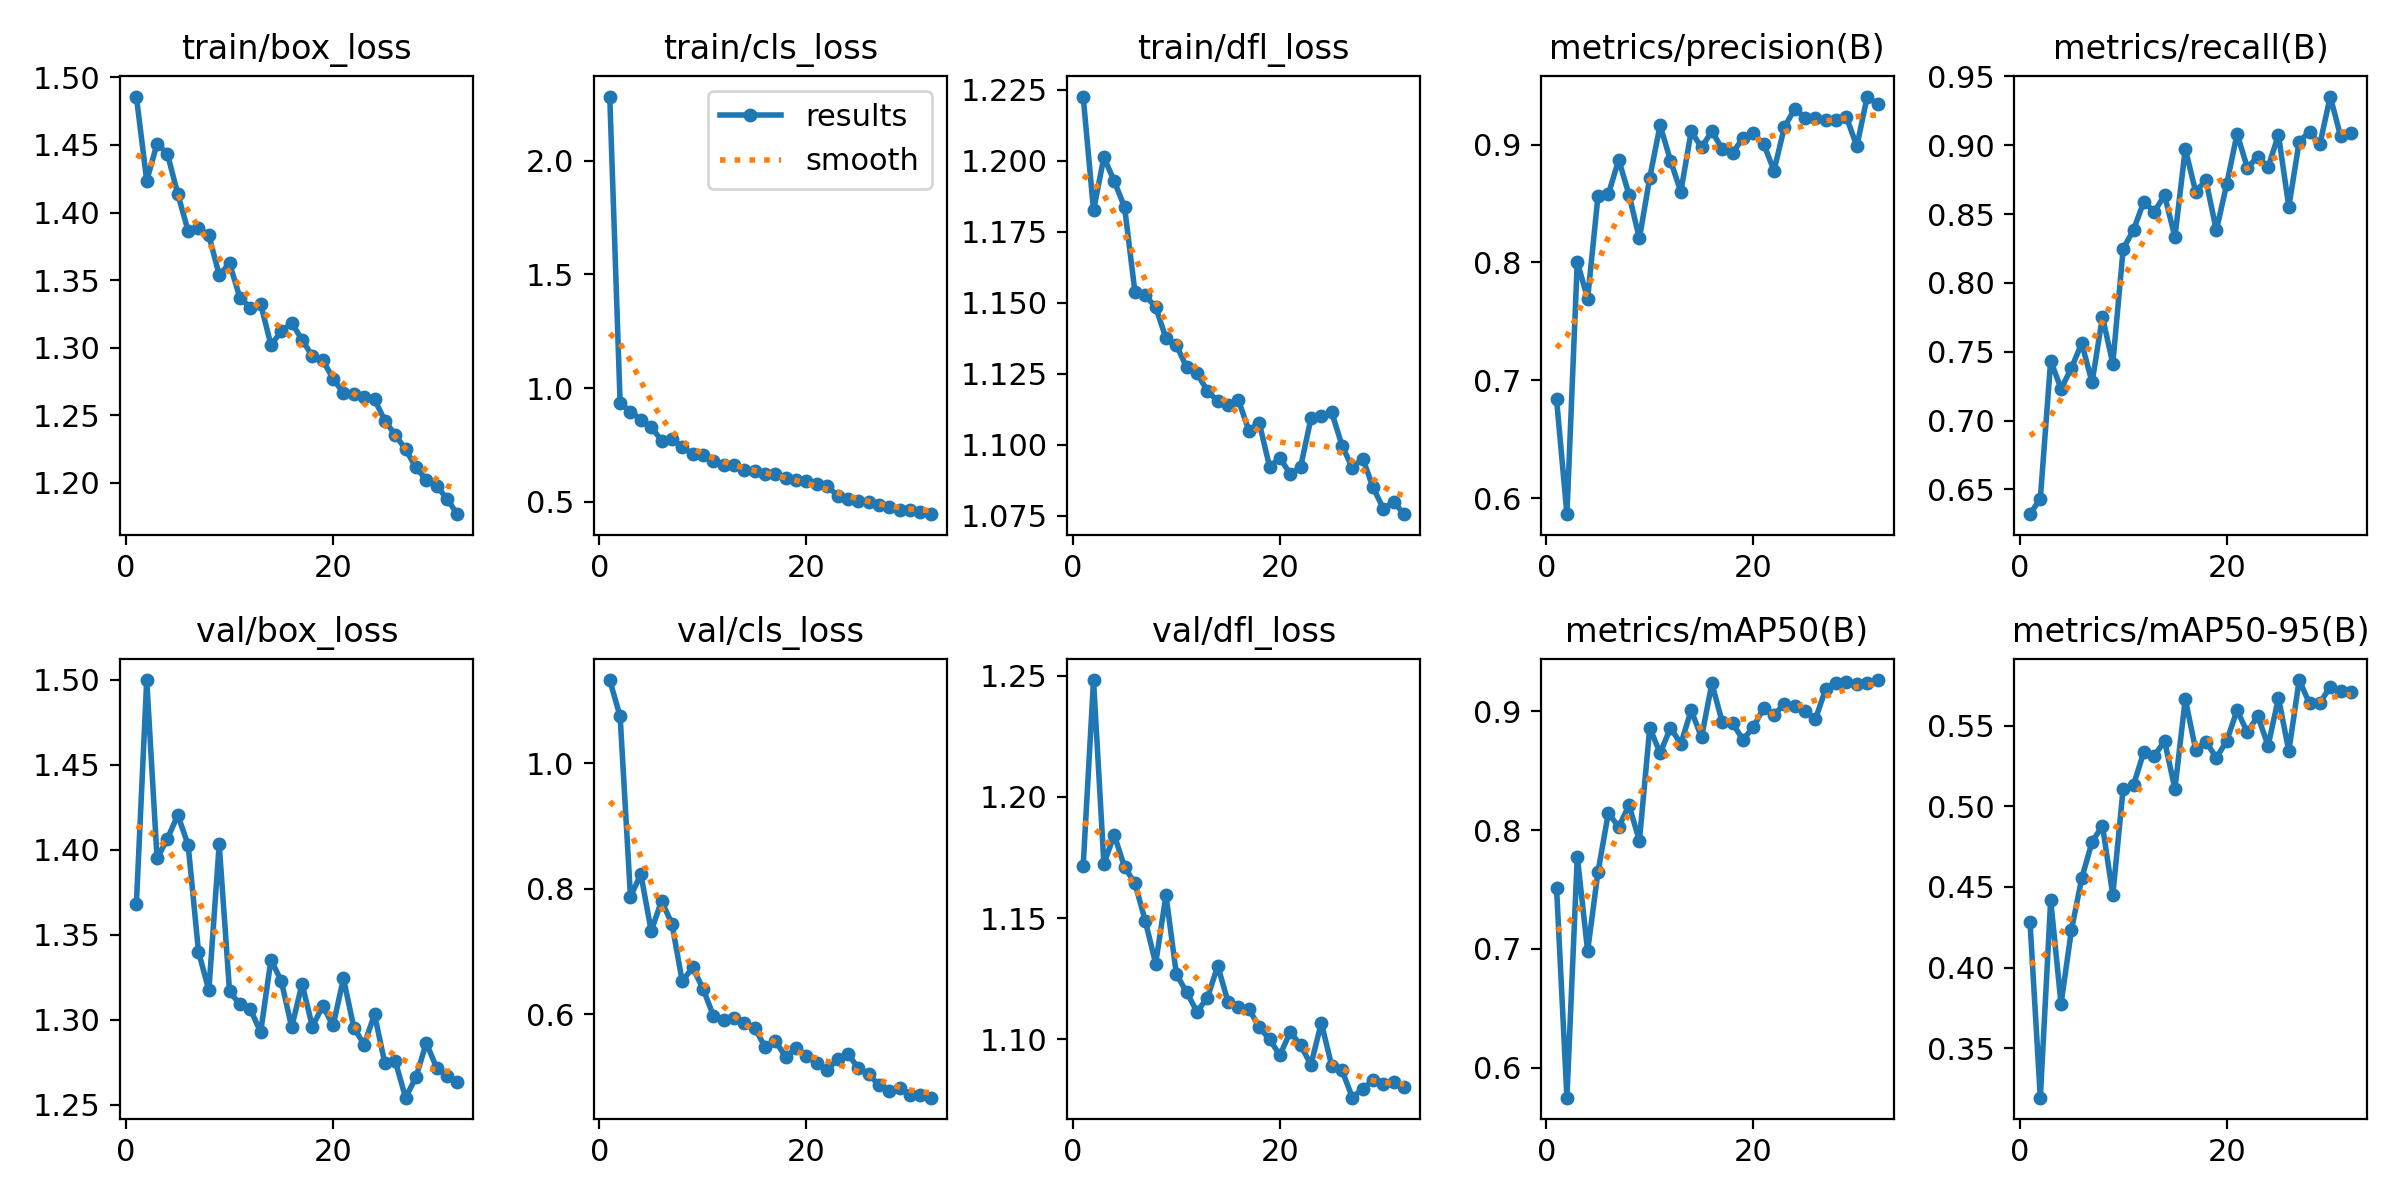


--- Showing: BoxPR_curve.png ---


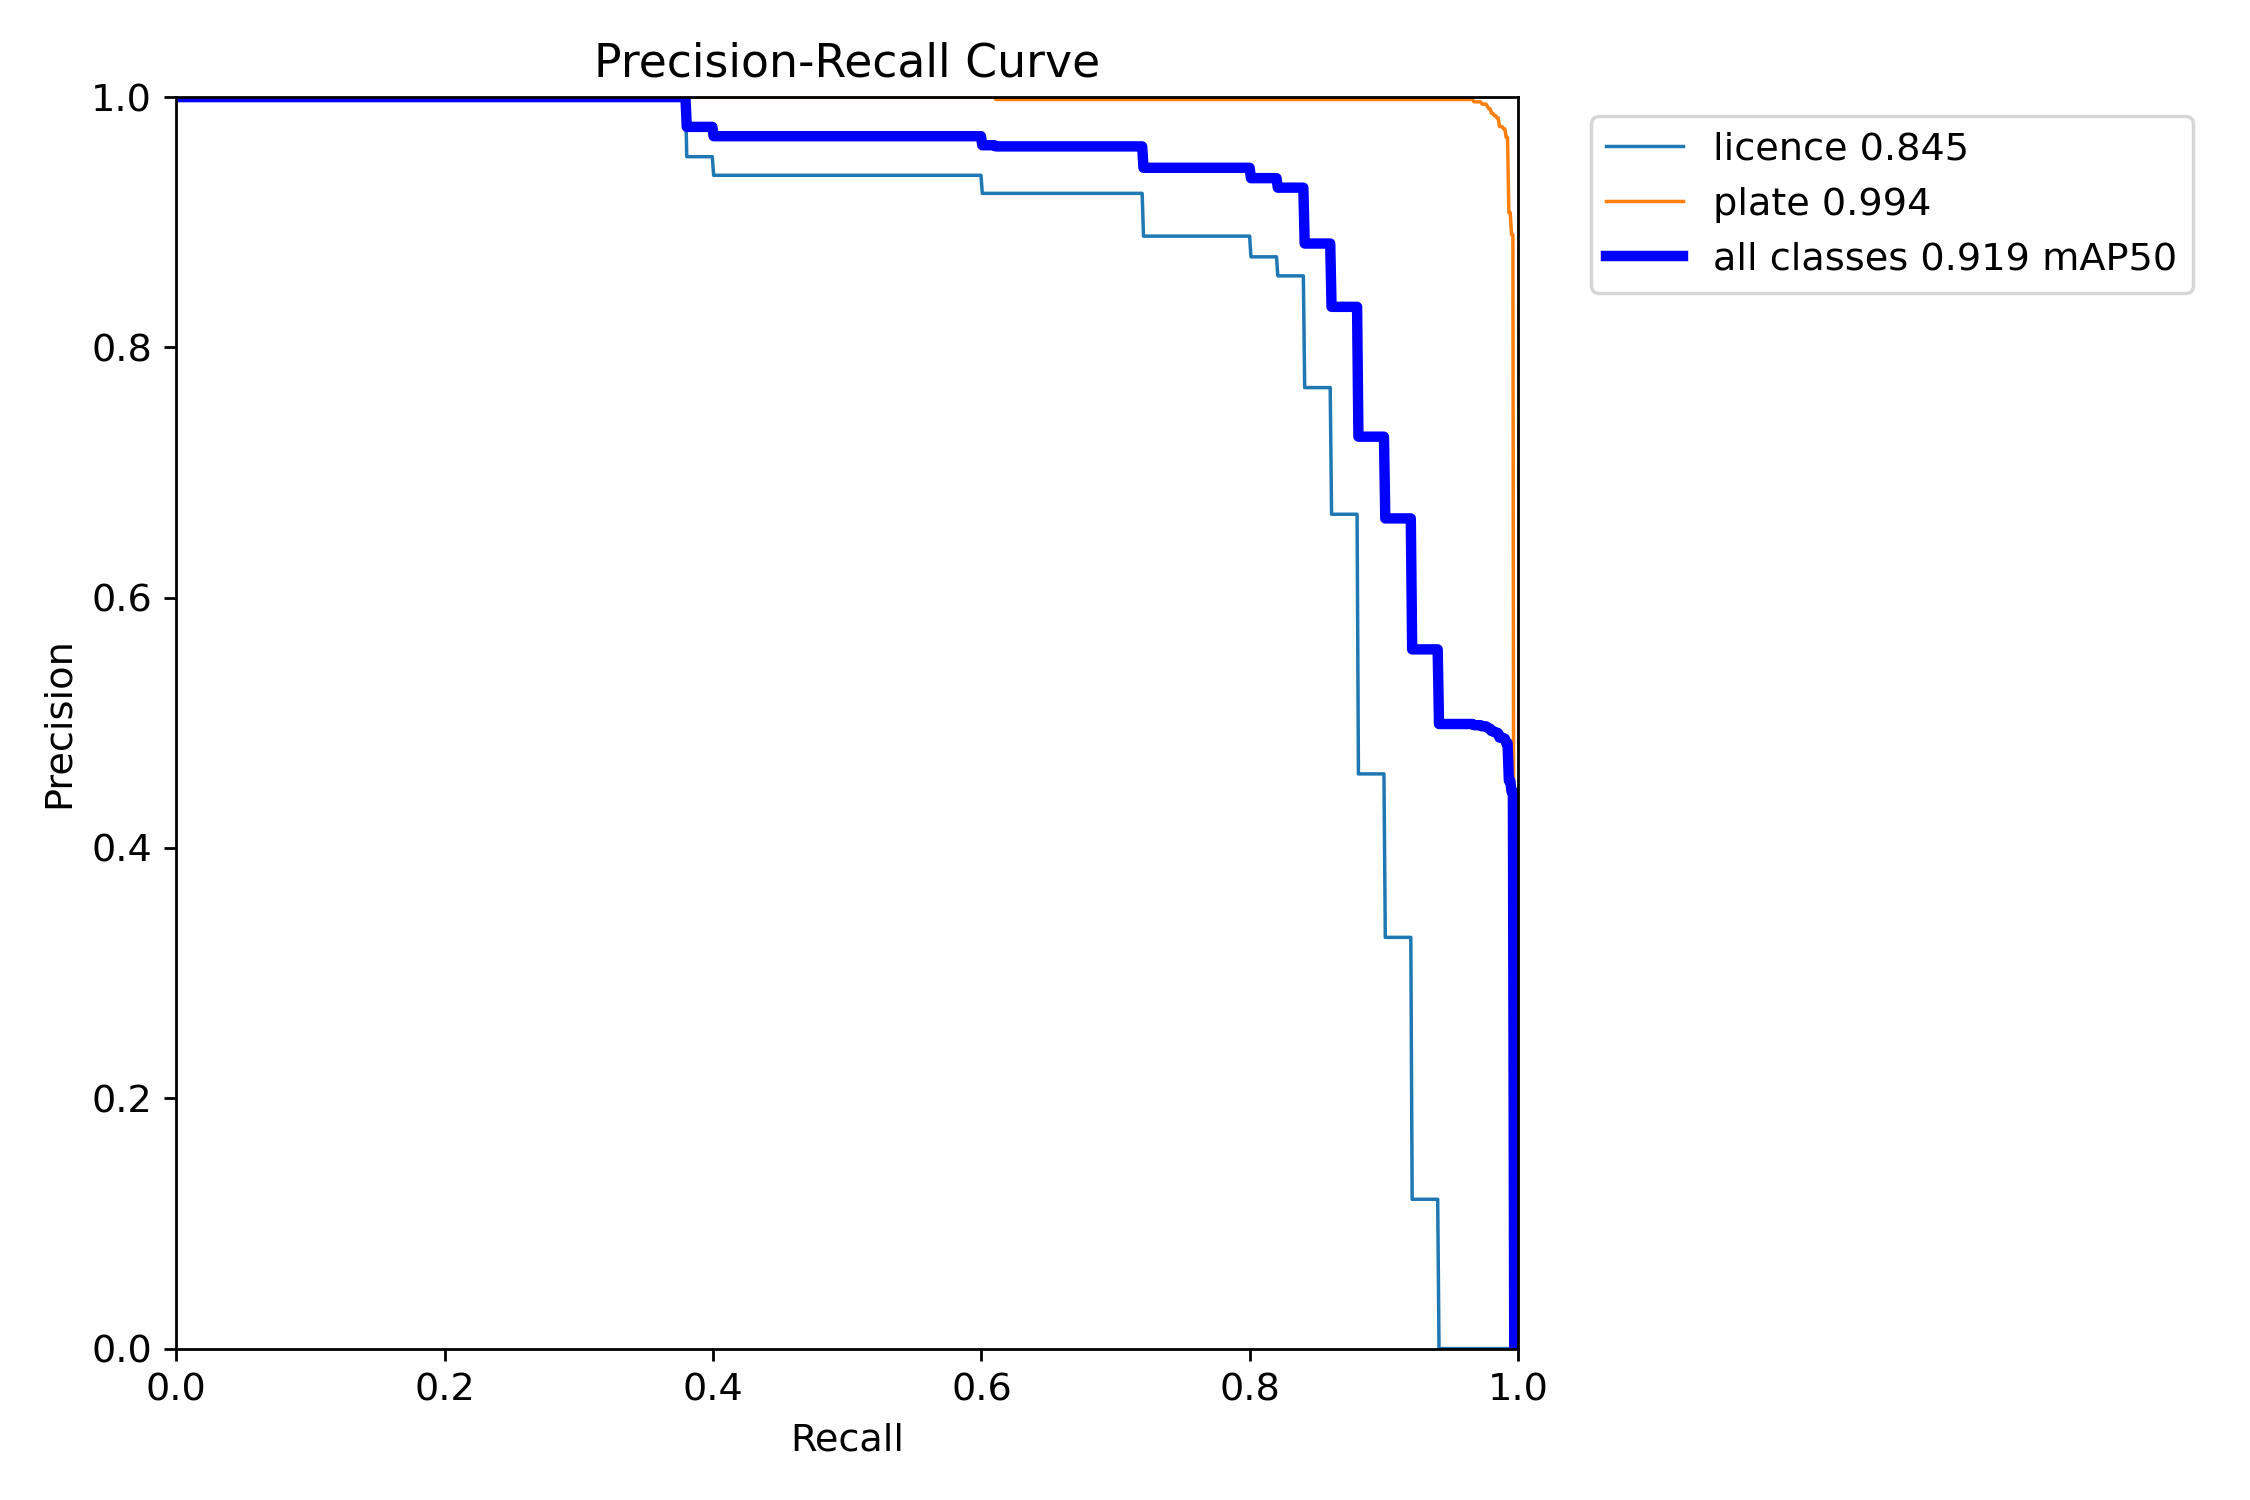

[Info] PR_curve.png not found for v8n

--- Showing: confusion_matrix_normalized.png ---


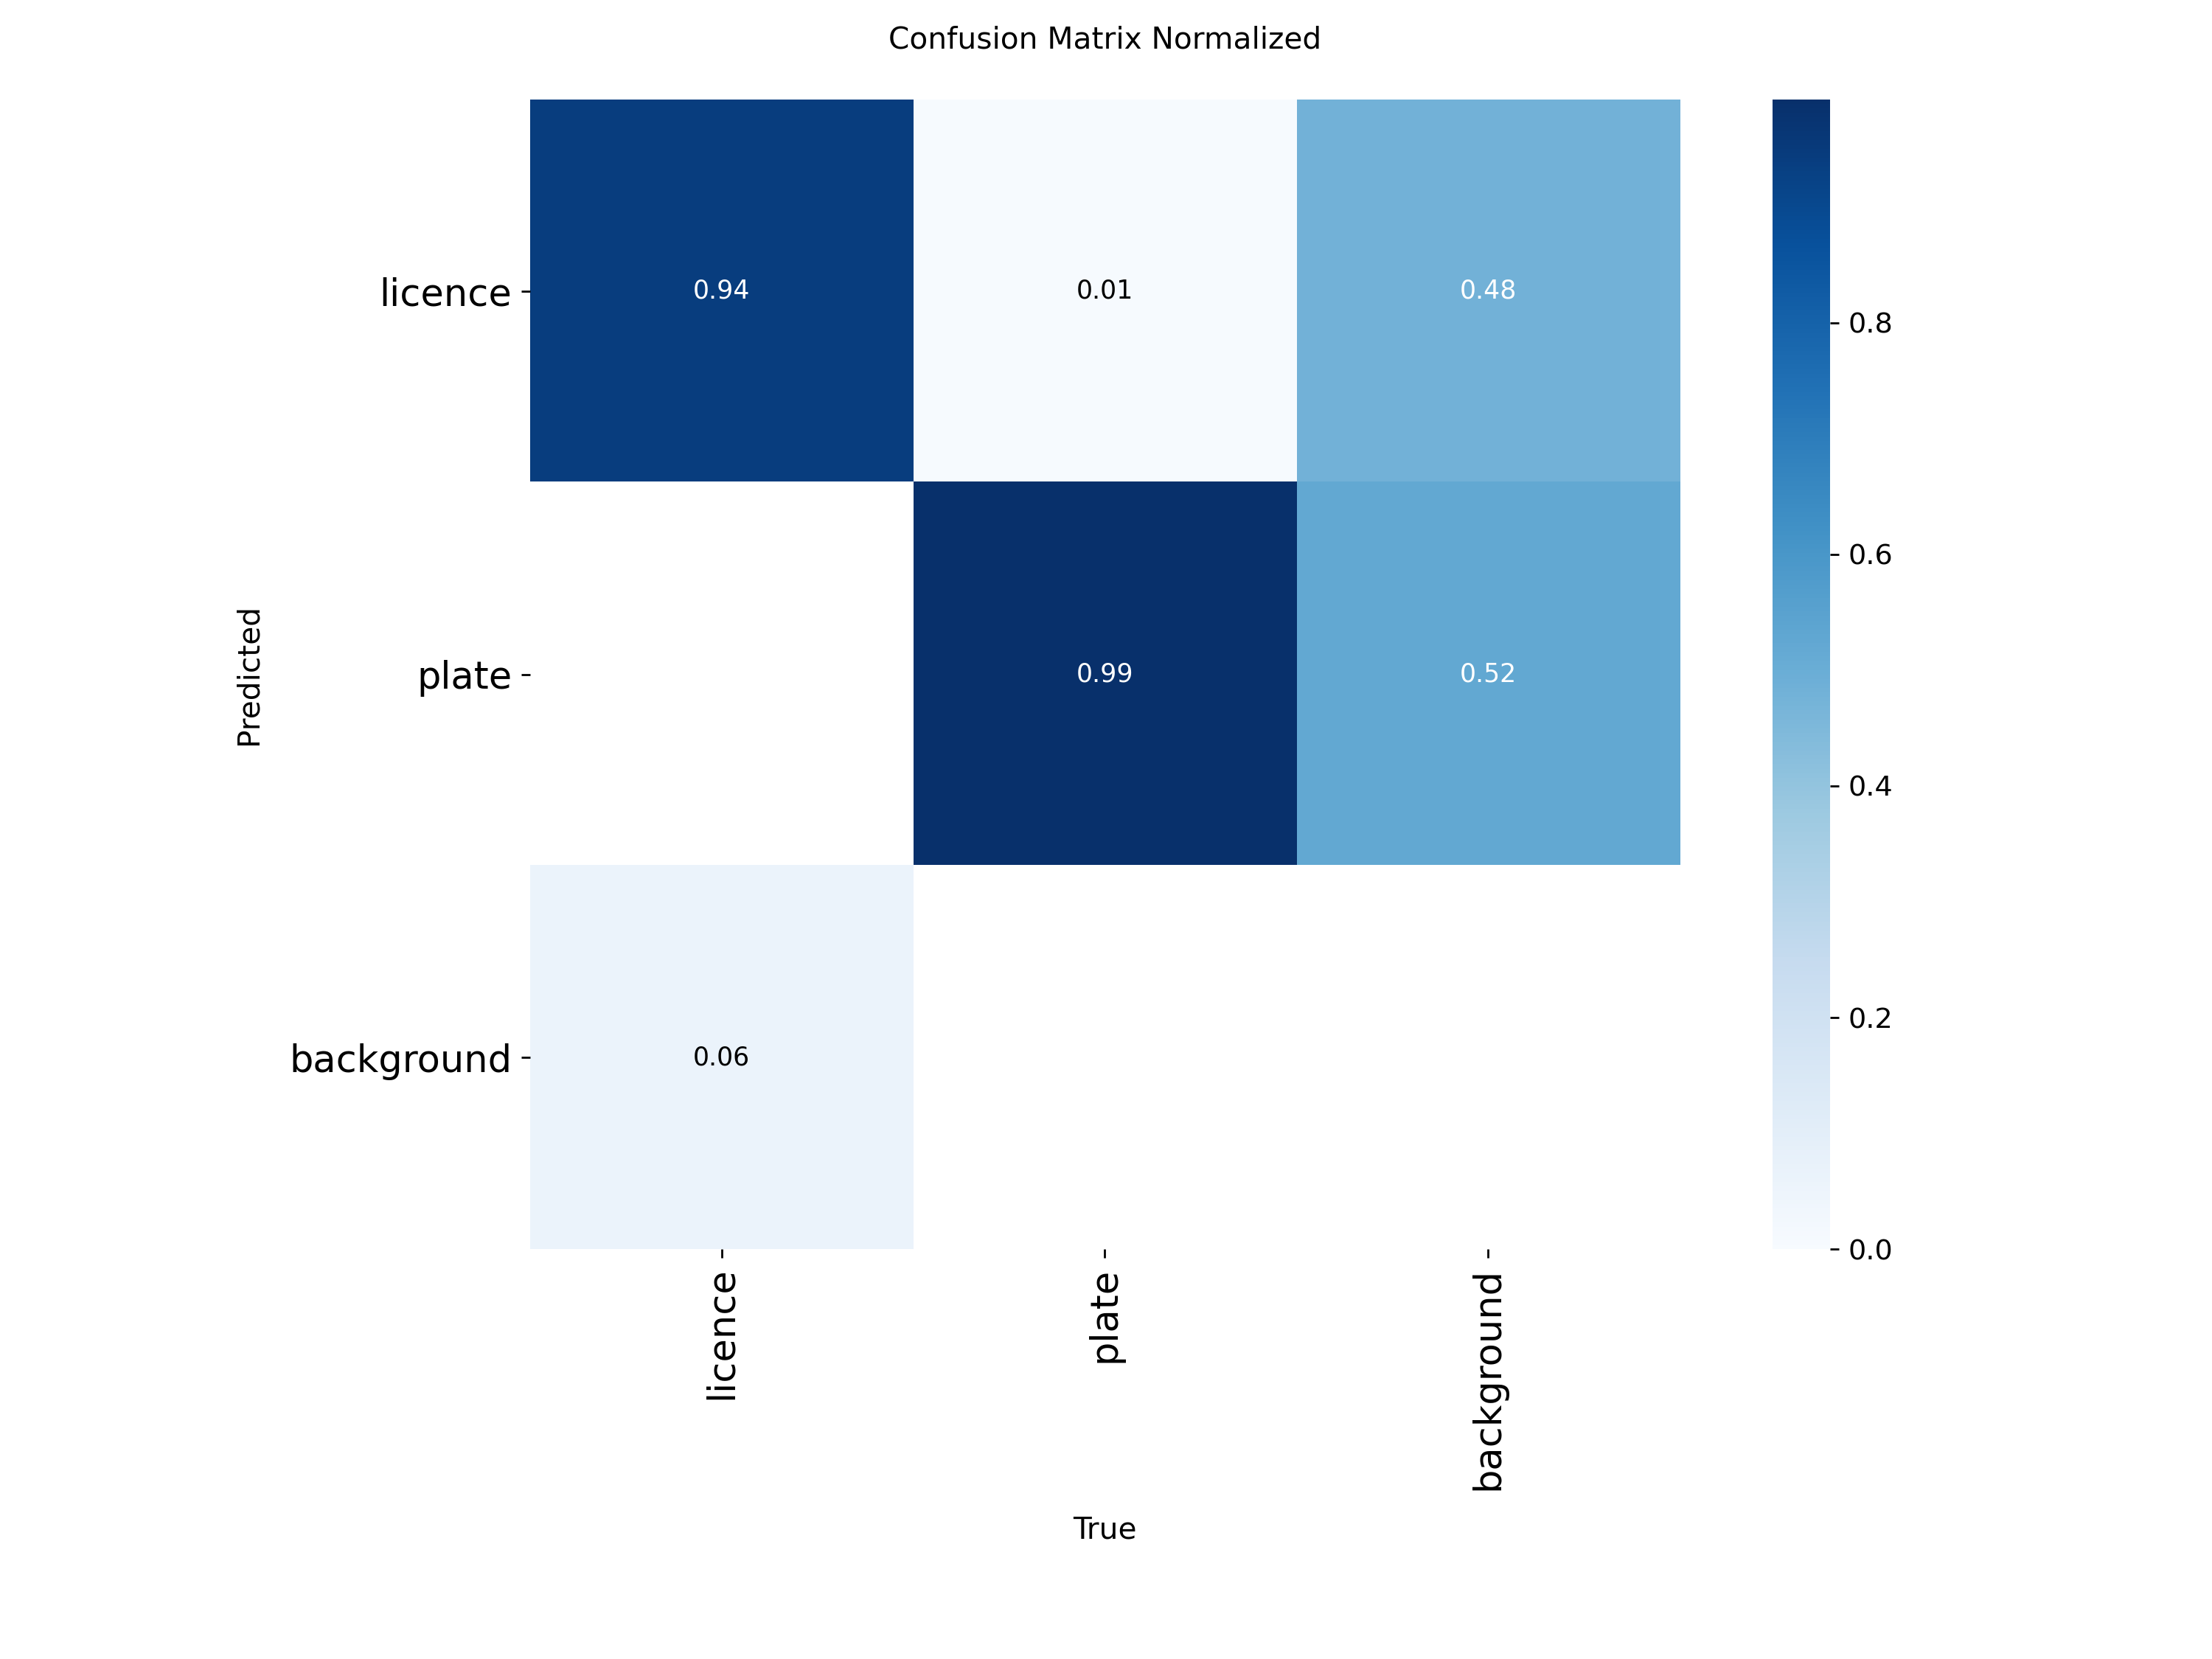


--- Showing: confusion_matrix.png ---


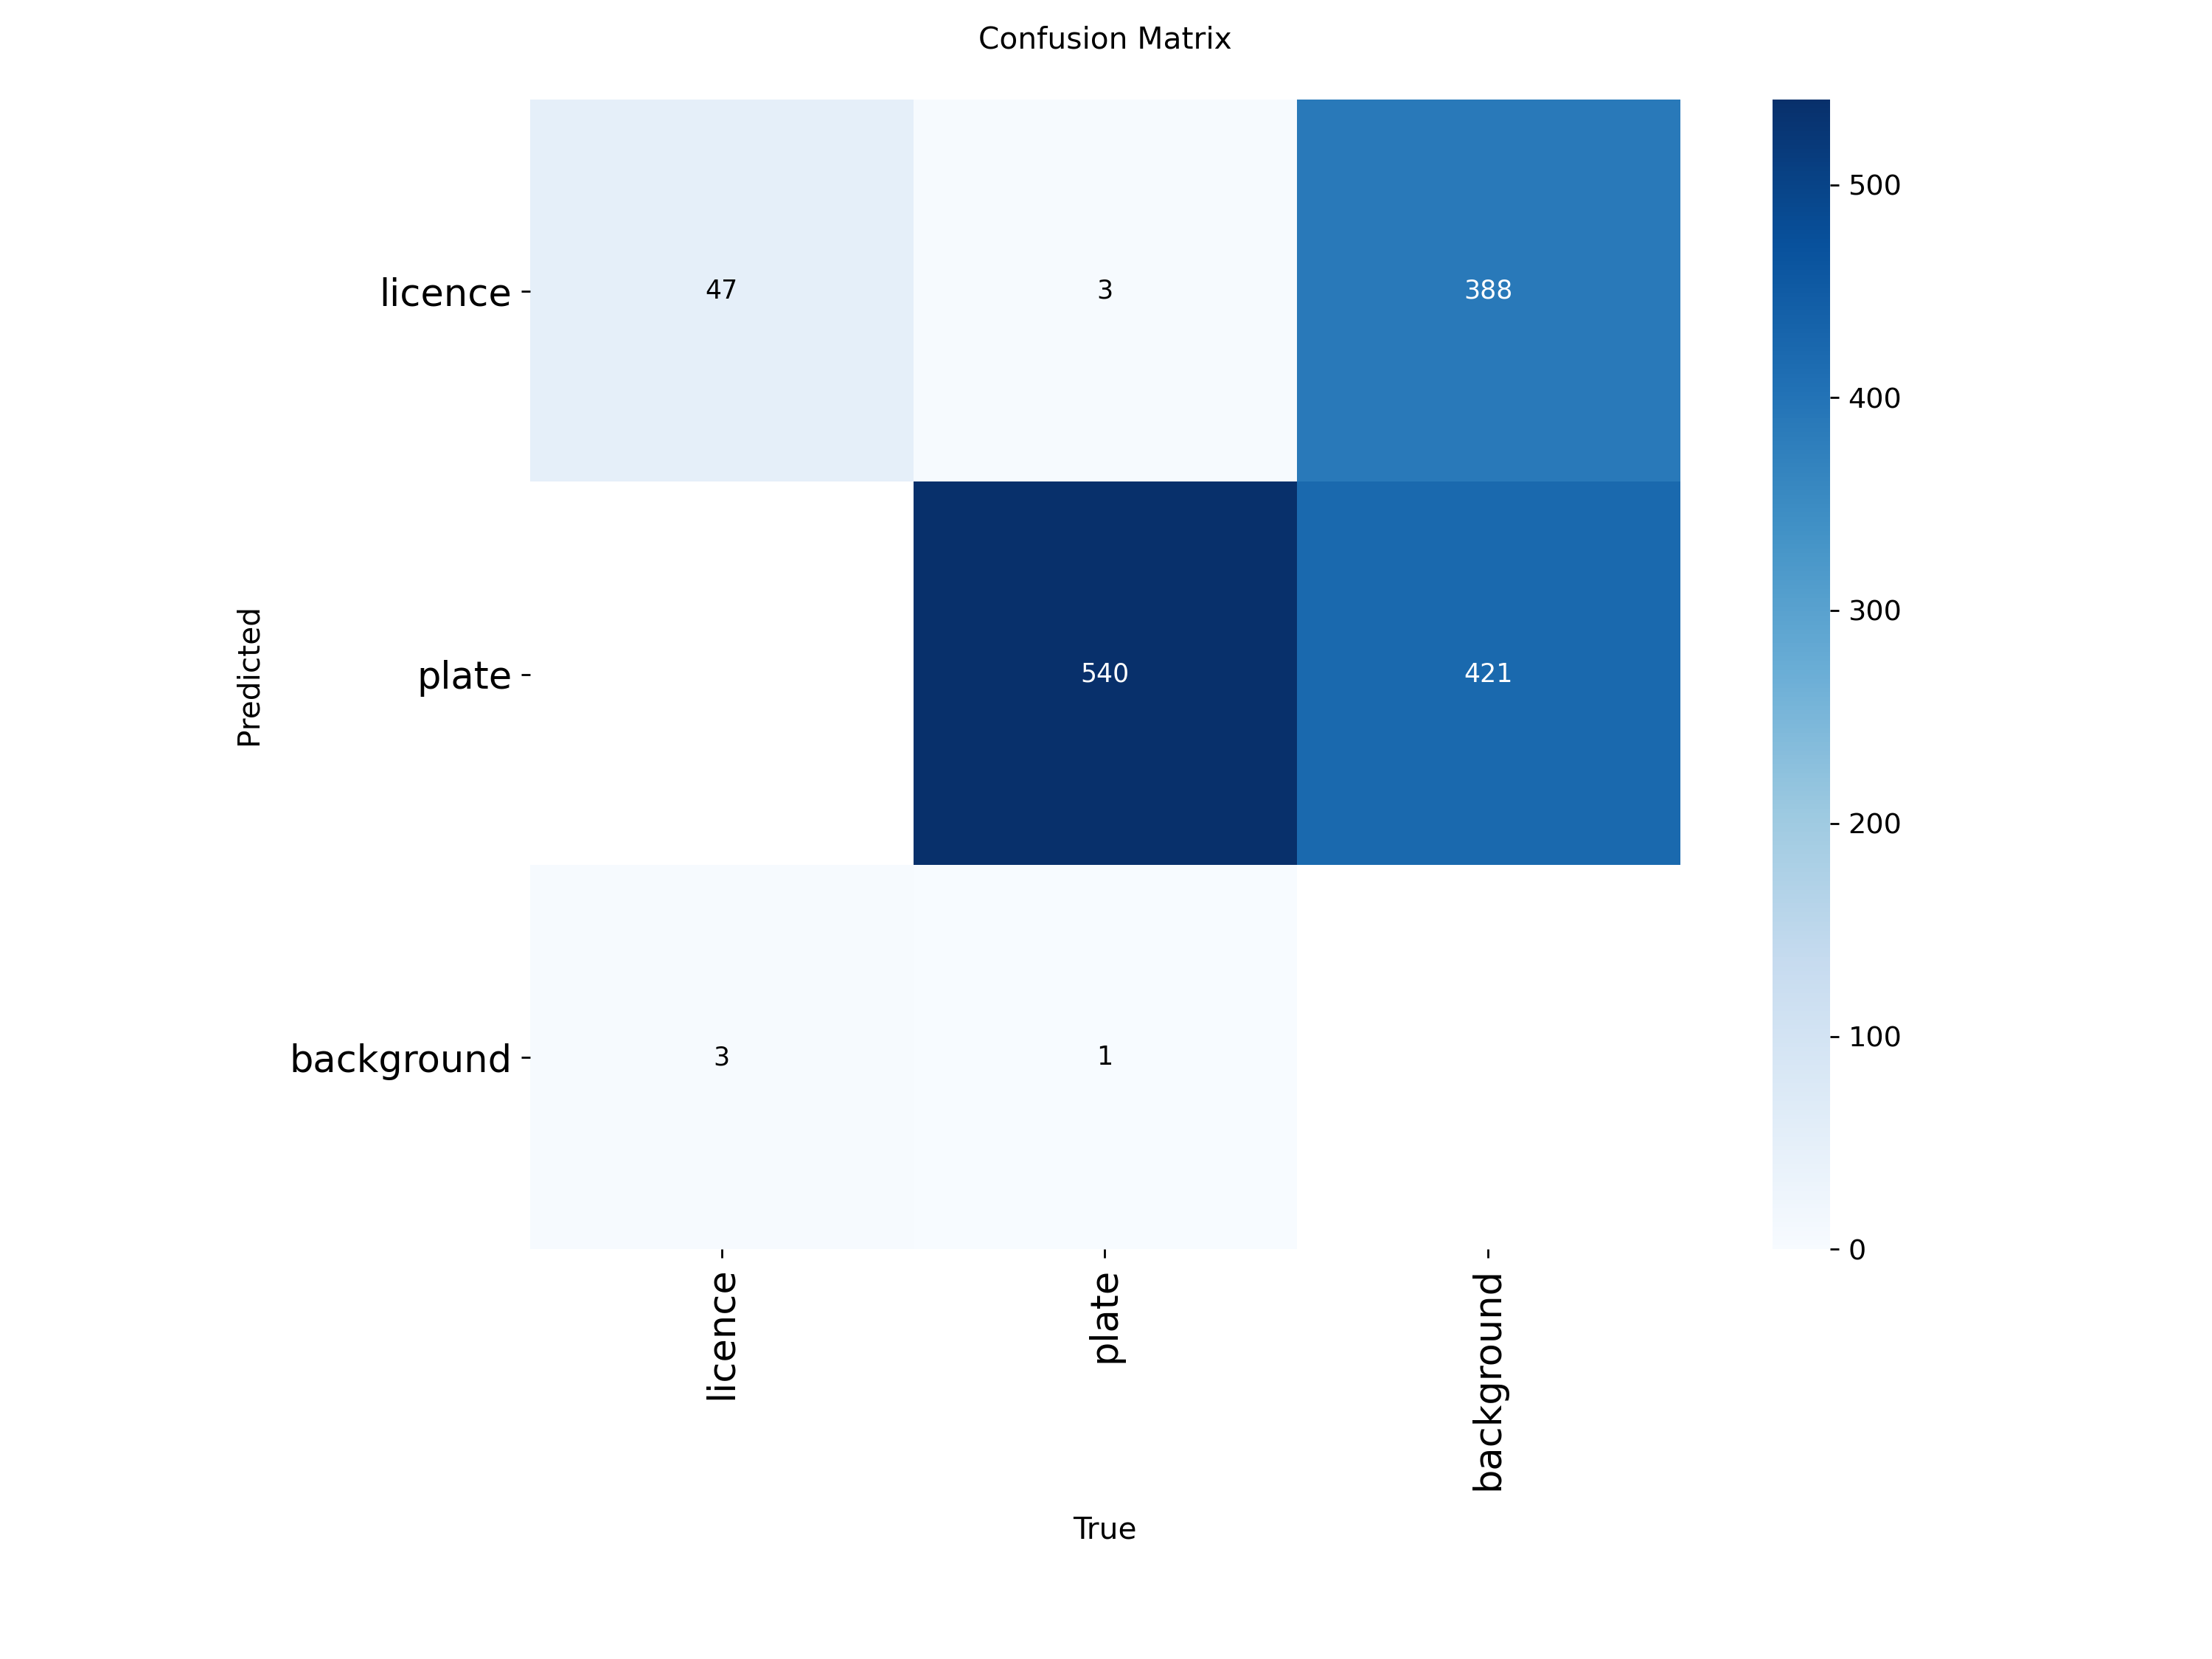


===== Y26N Training Curves & Performance Figures =====

--- Showing: results.png ---


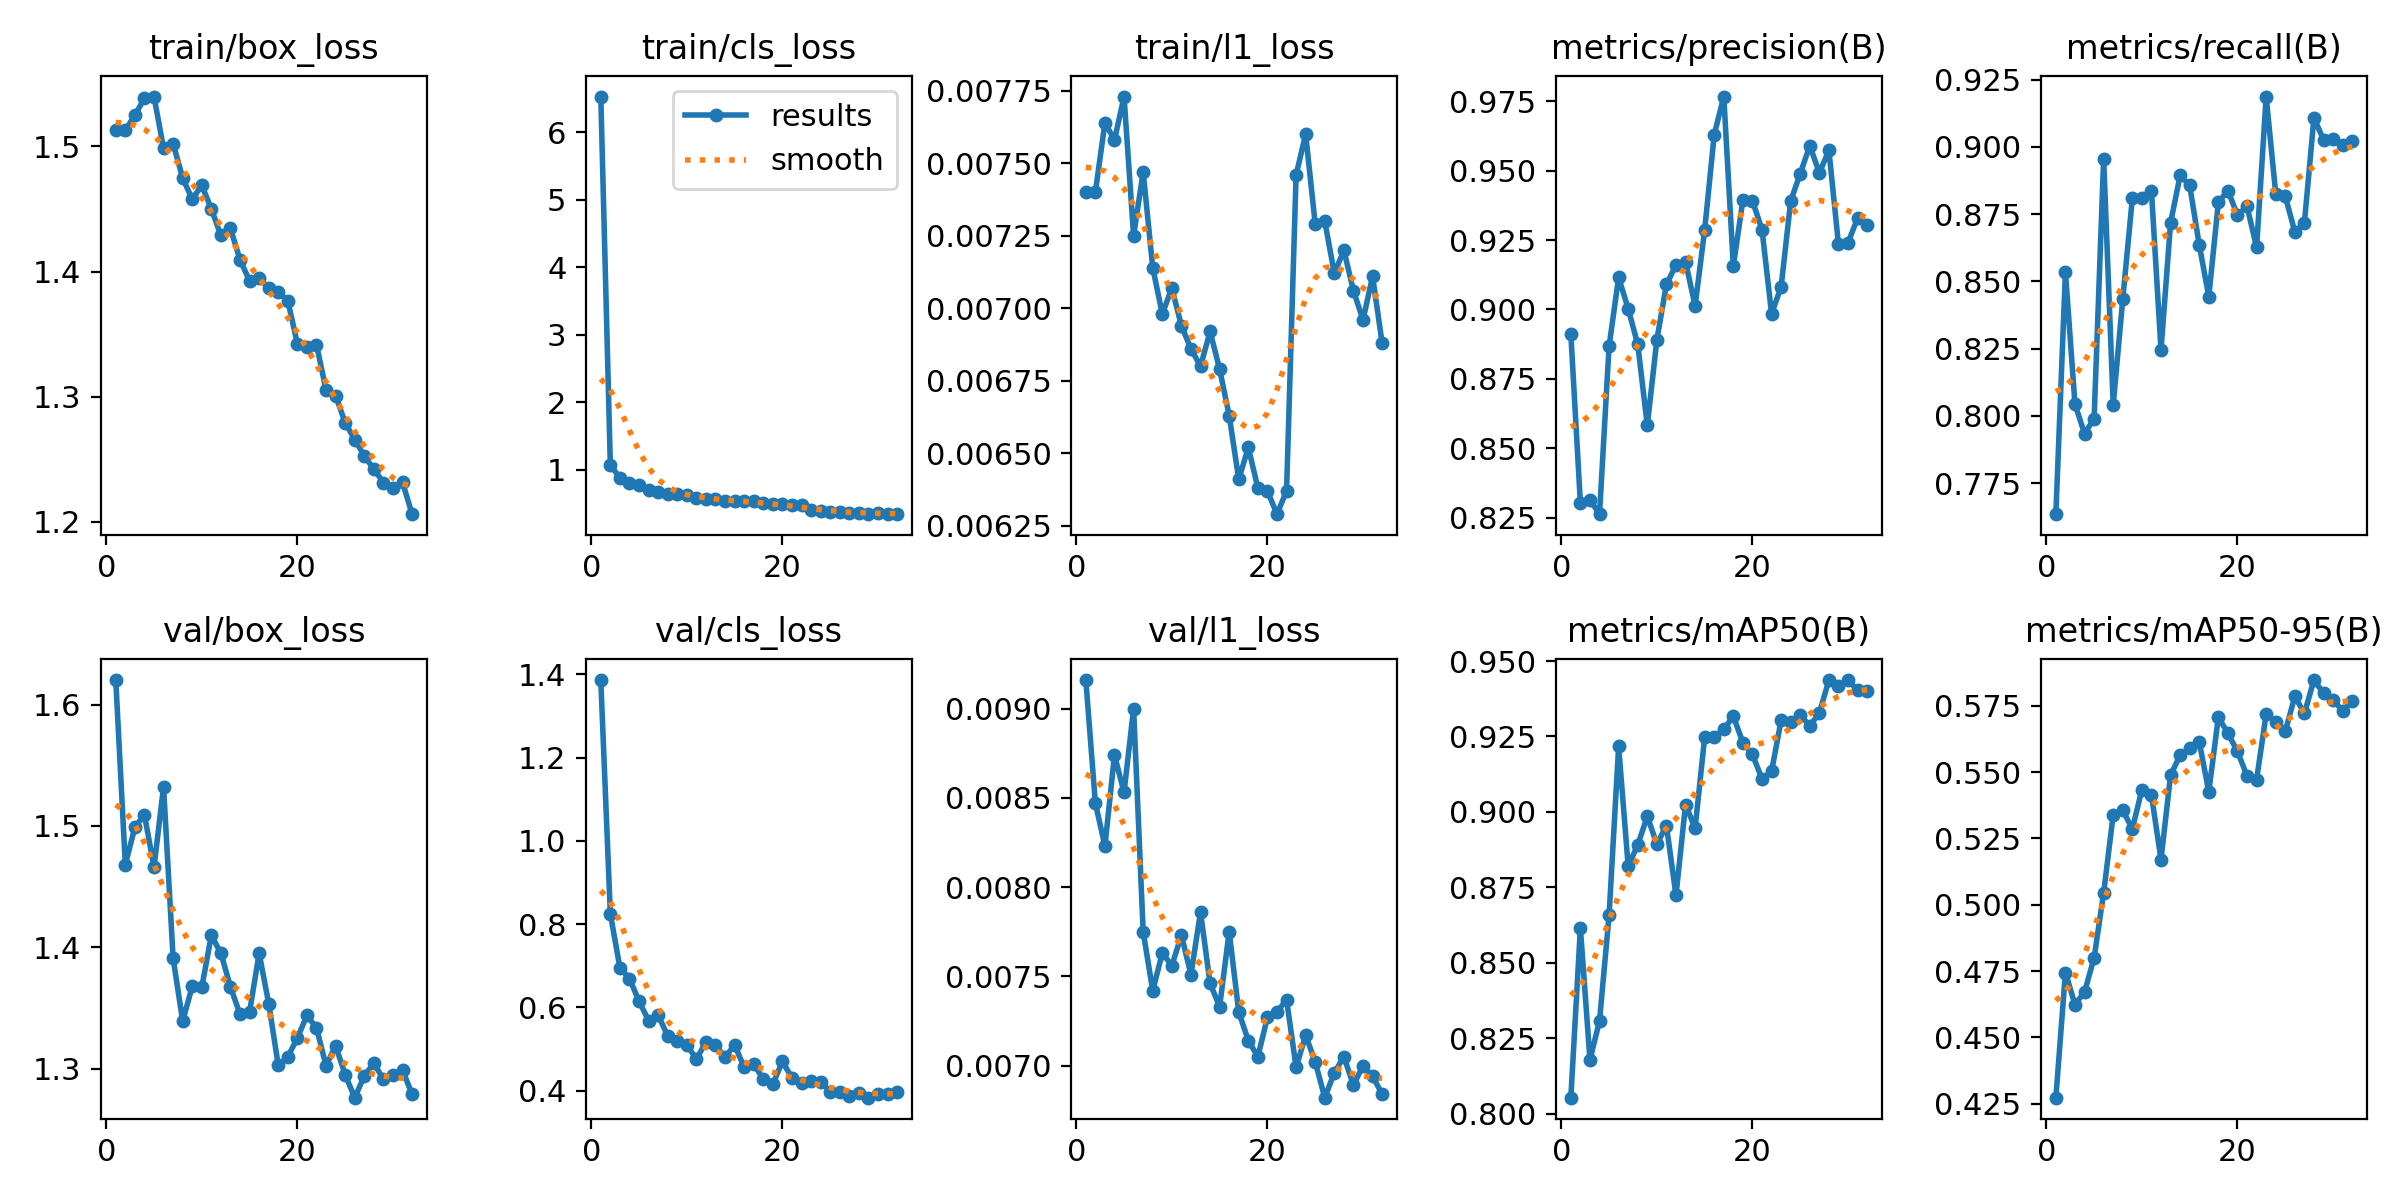


--- Showing: BoxPR_curve.png ---


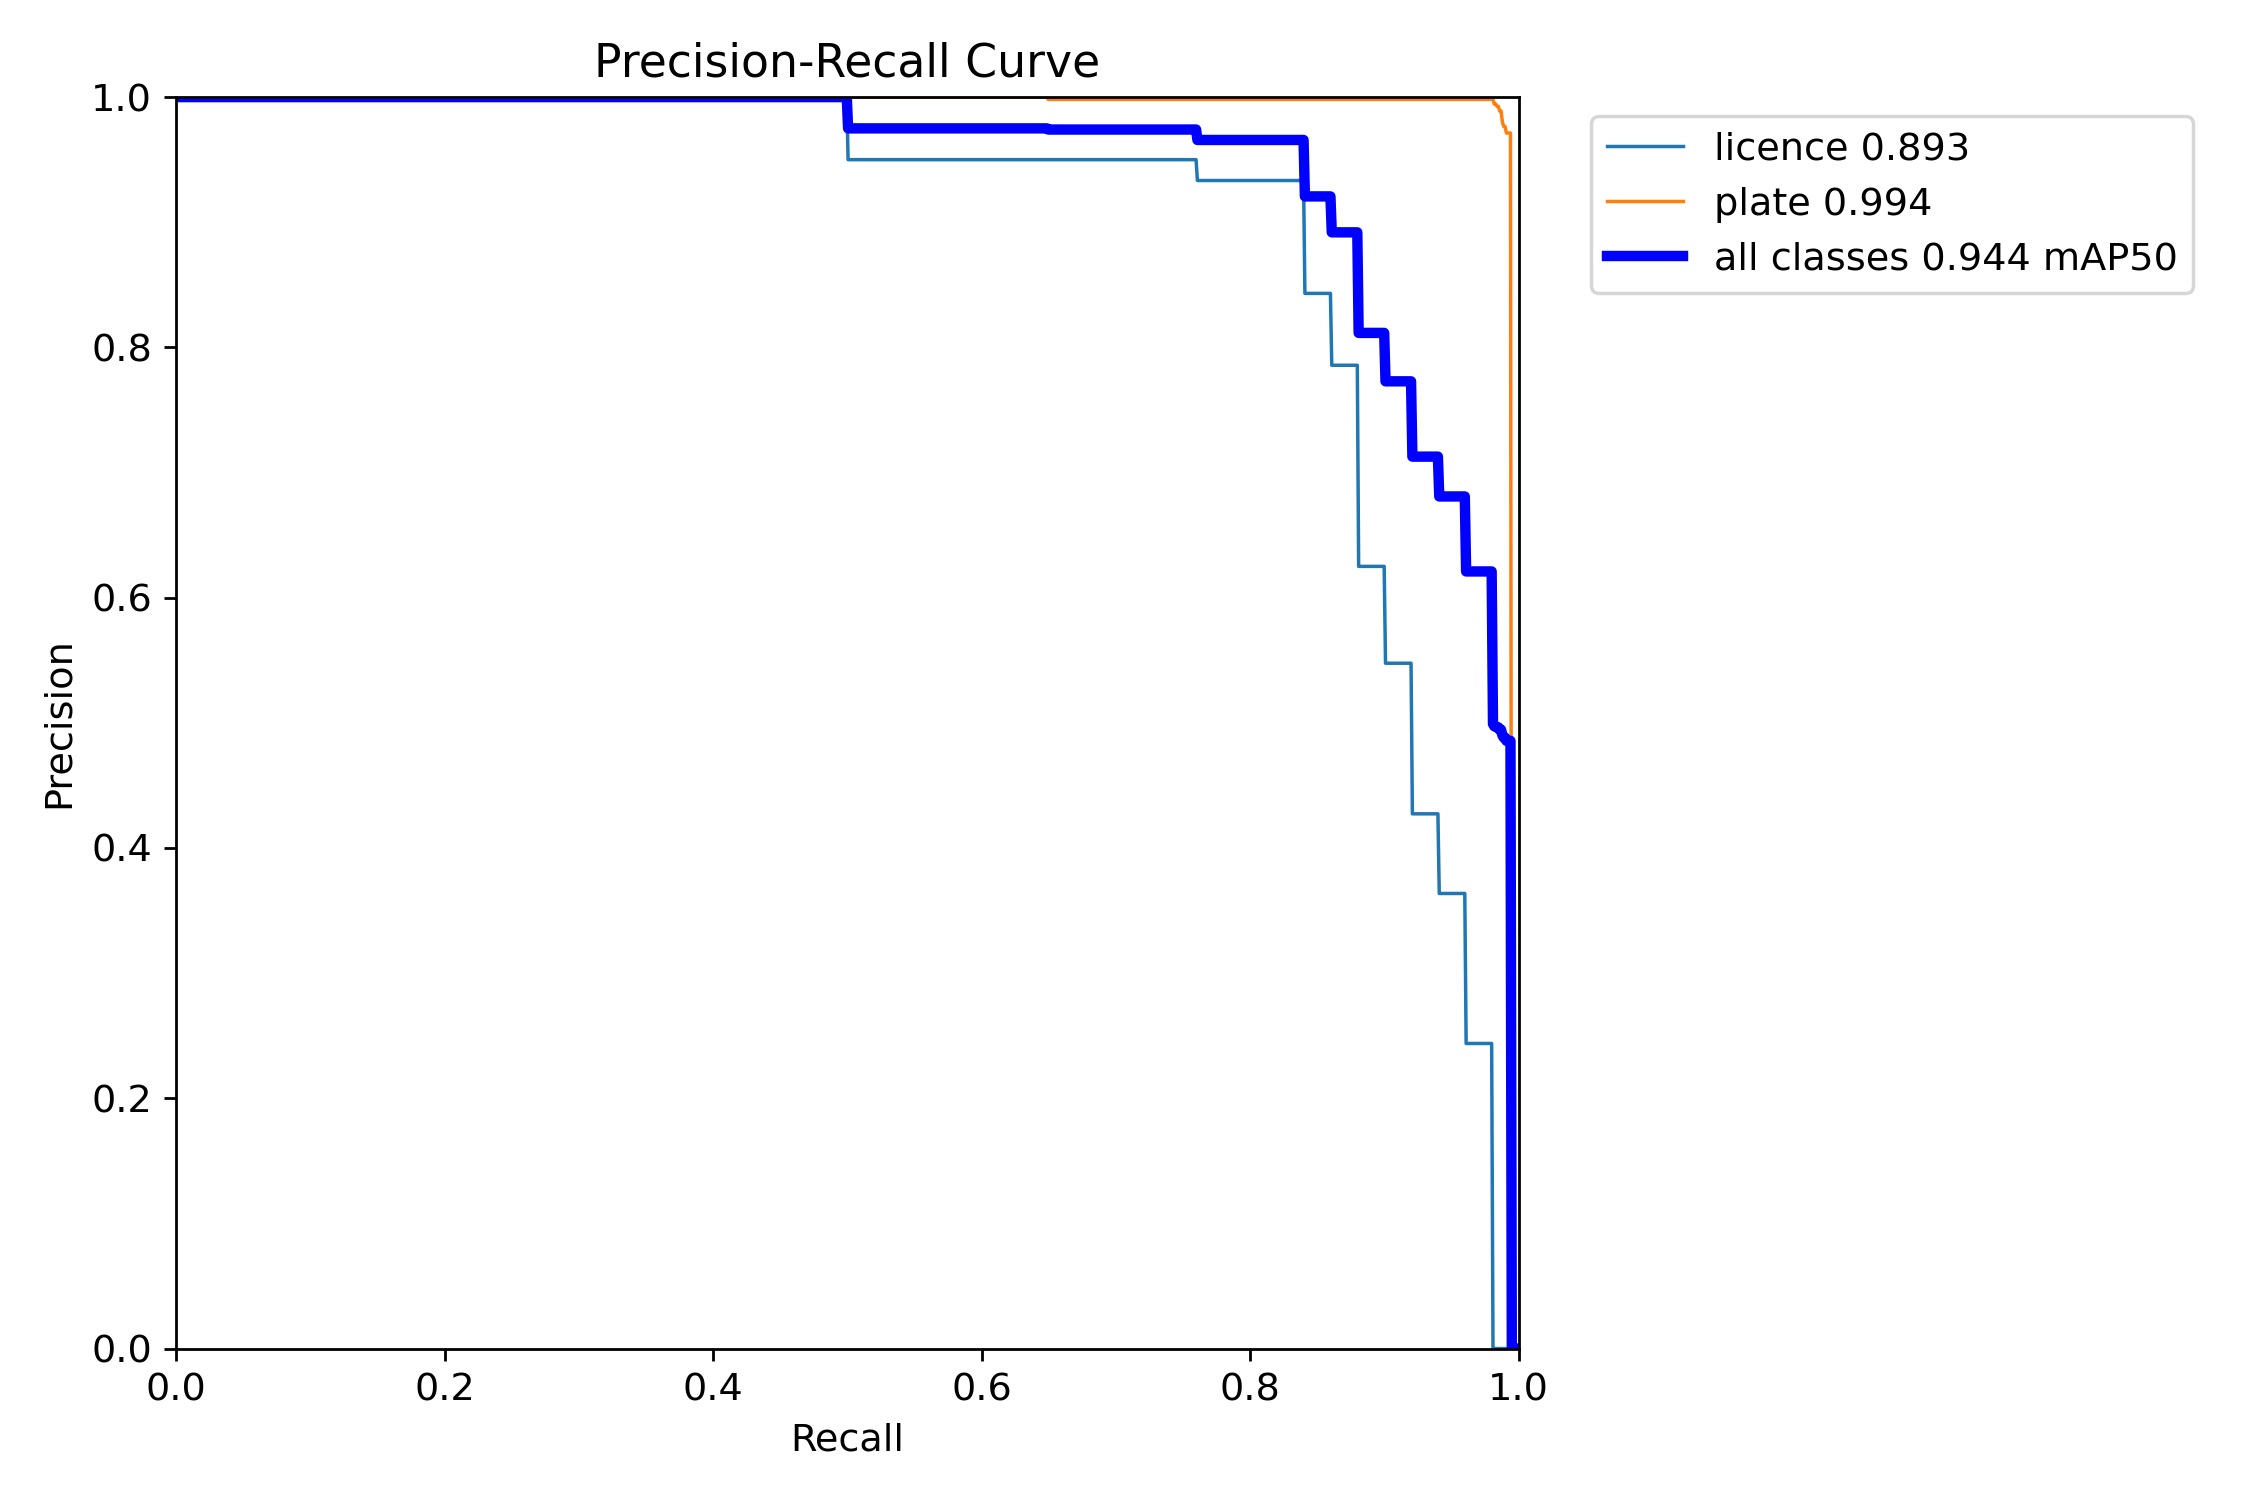

[Info] PR_curve.png not found for y26n

--- Showing: confusion_matrix_normalized.png ---


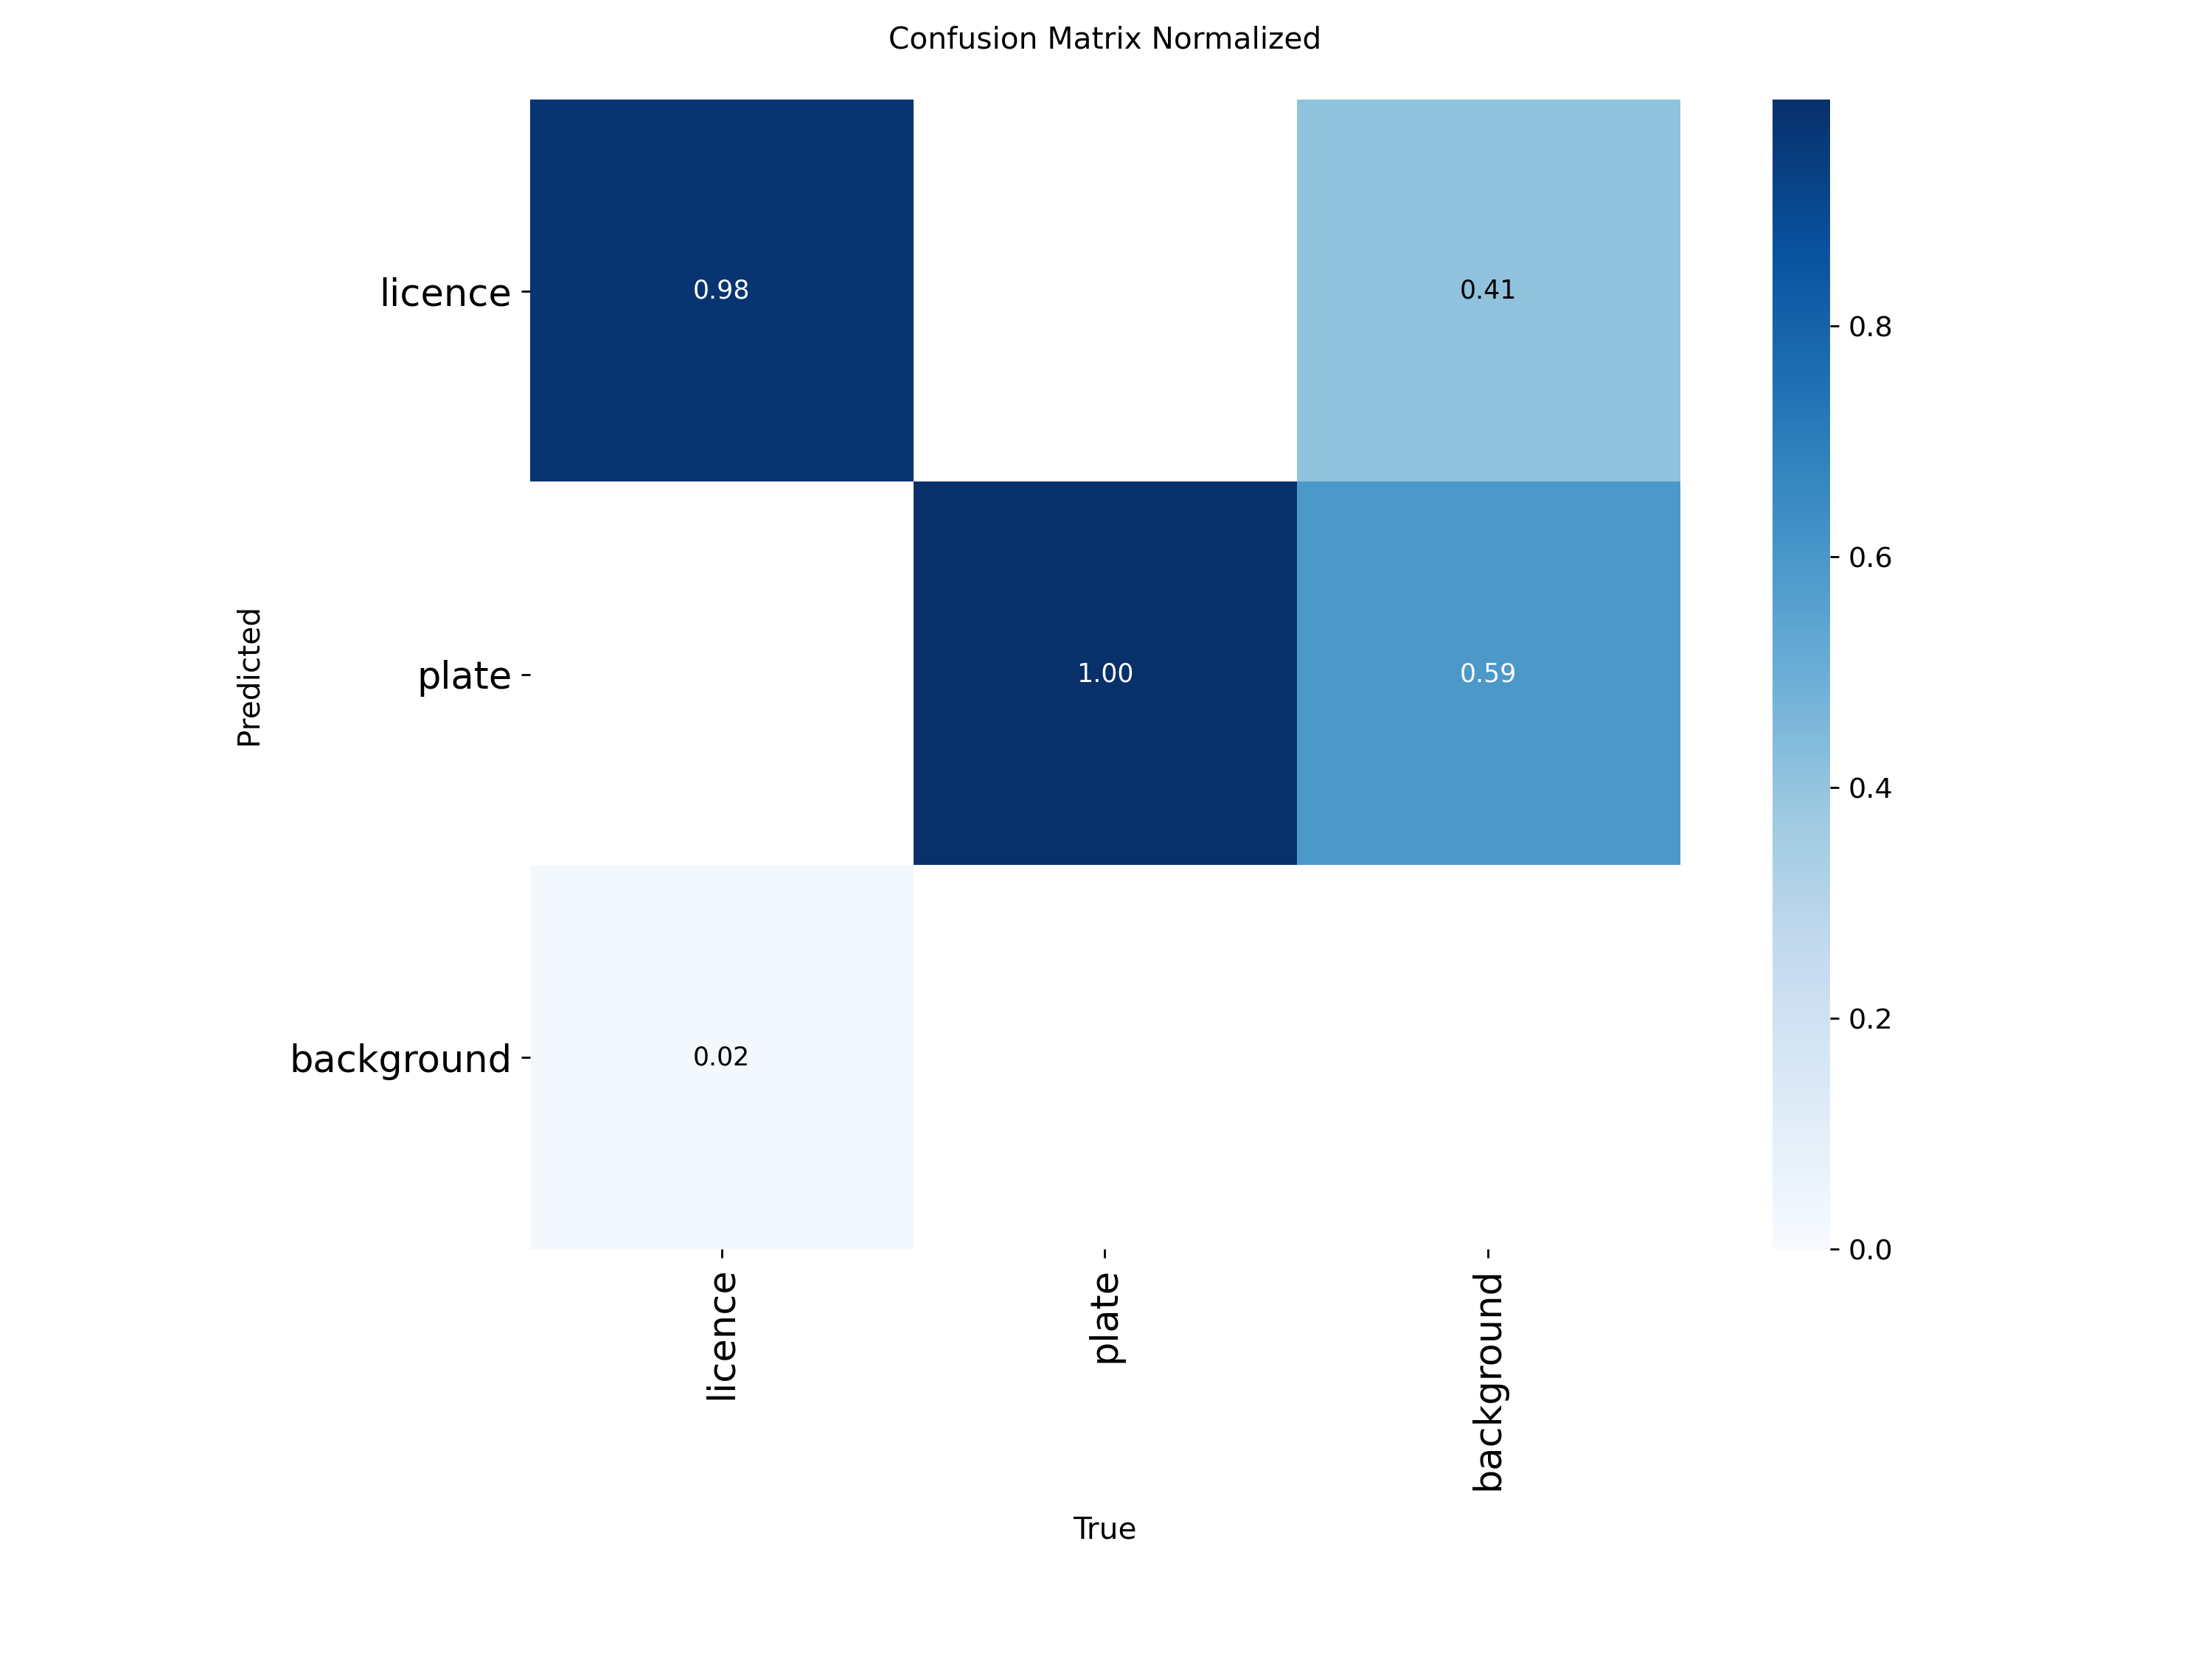


--- Showing: confusion_matrix.png ---


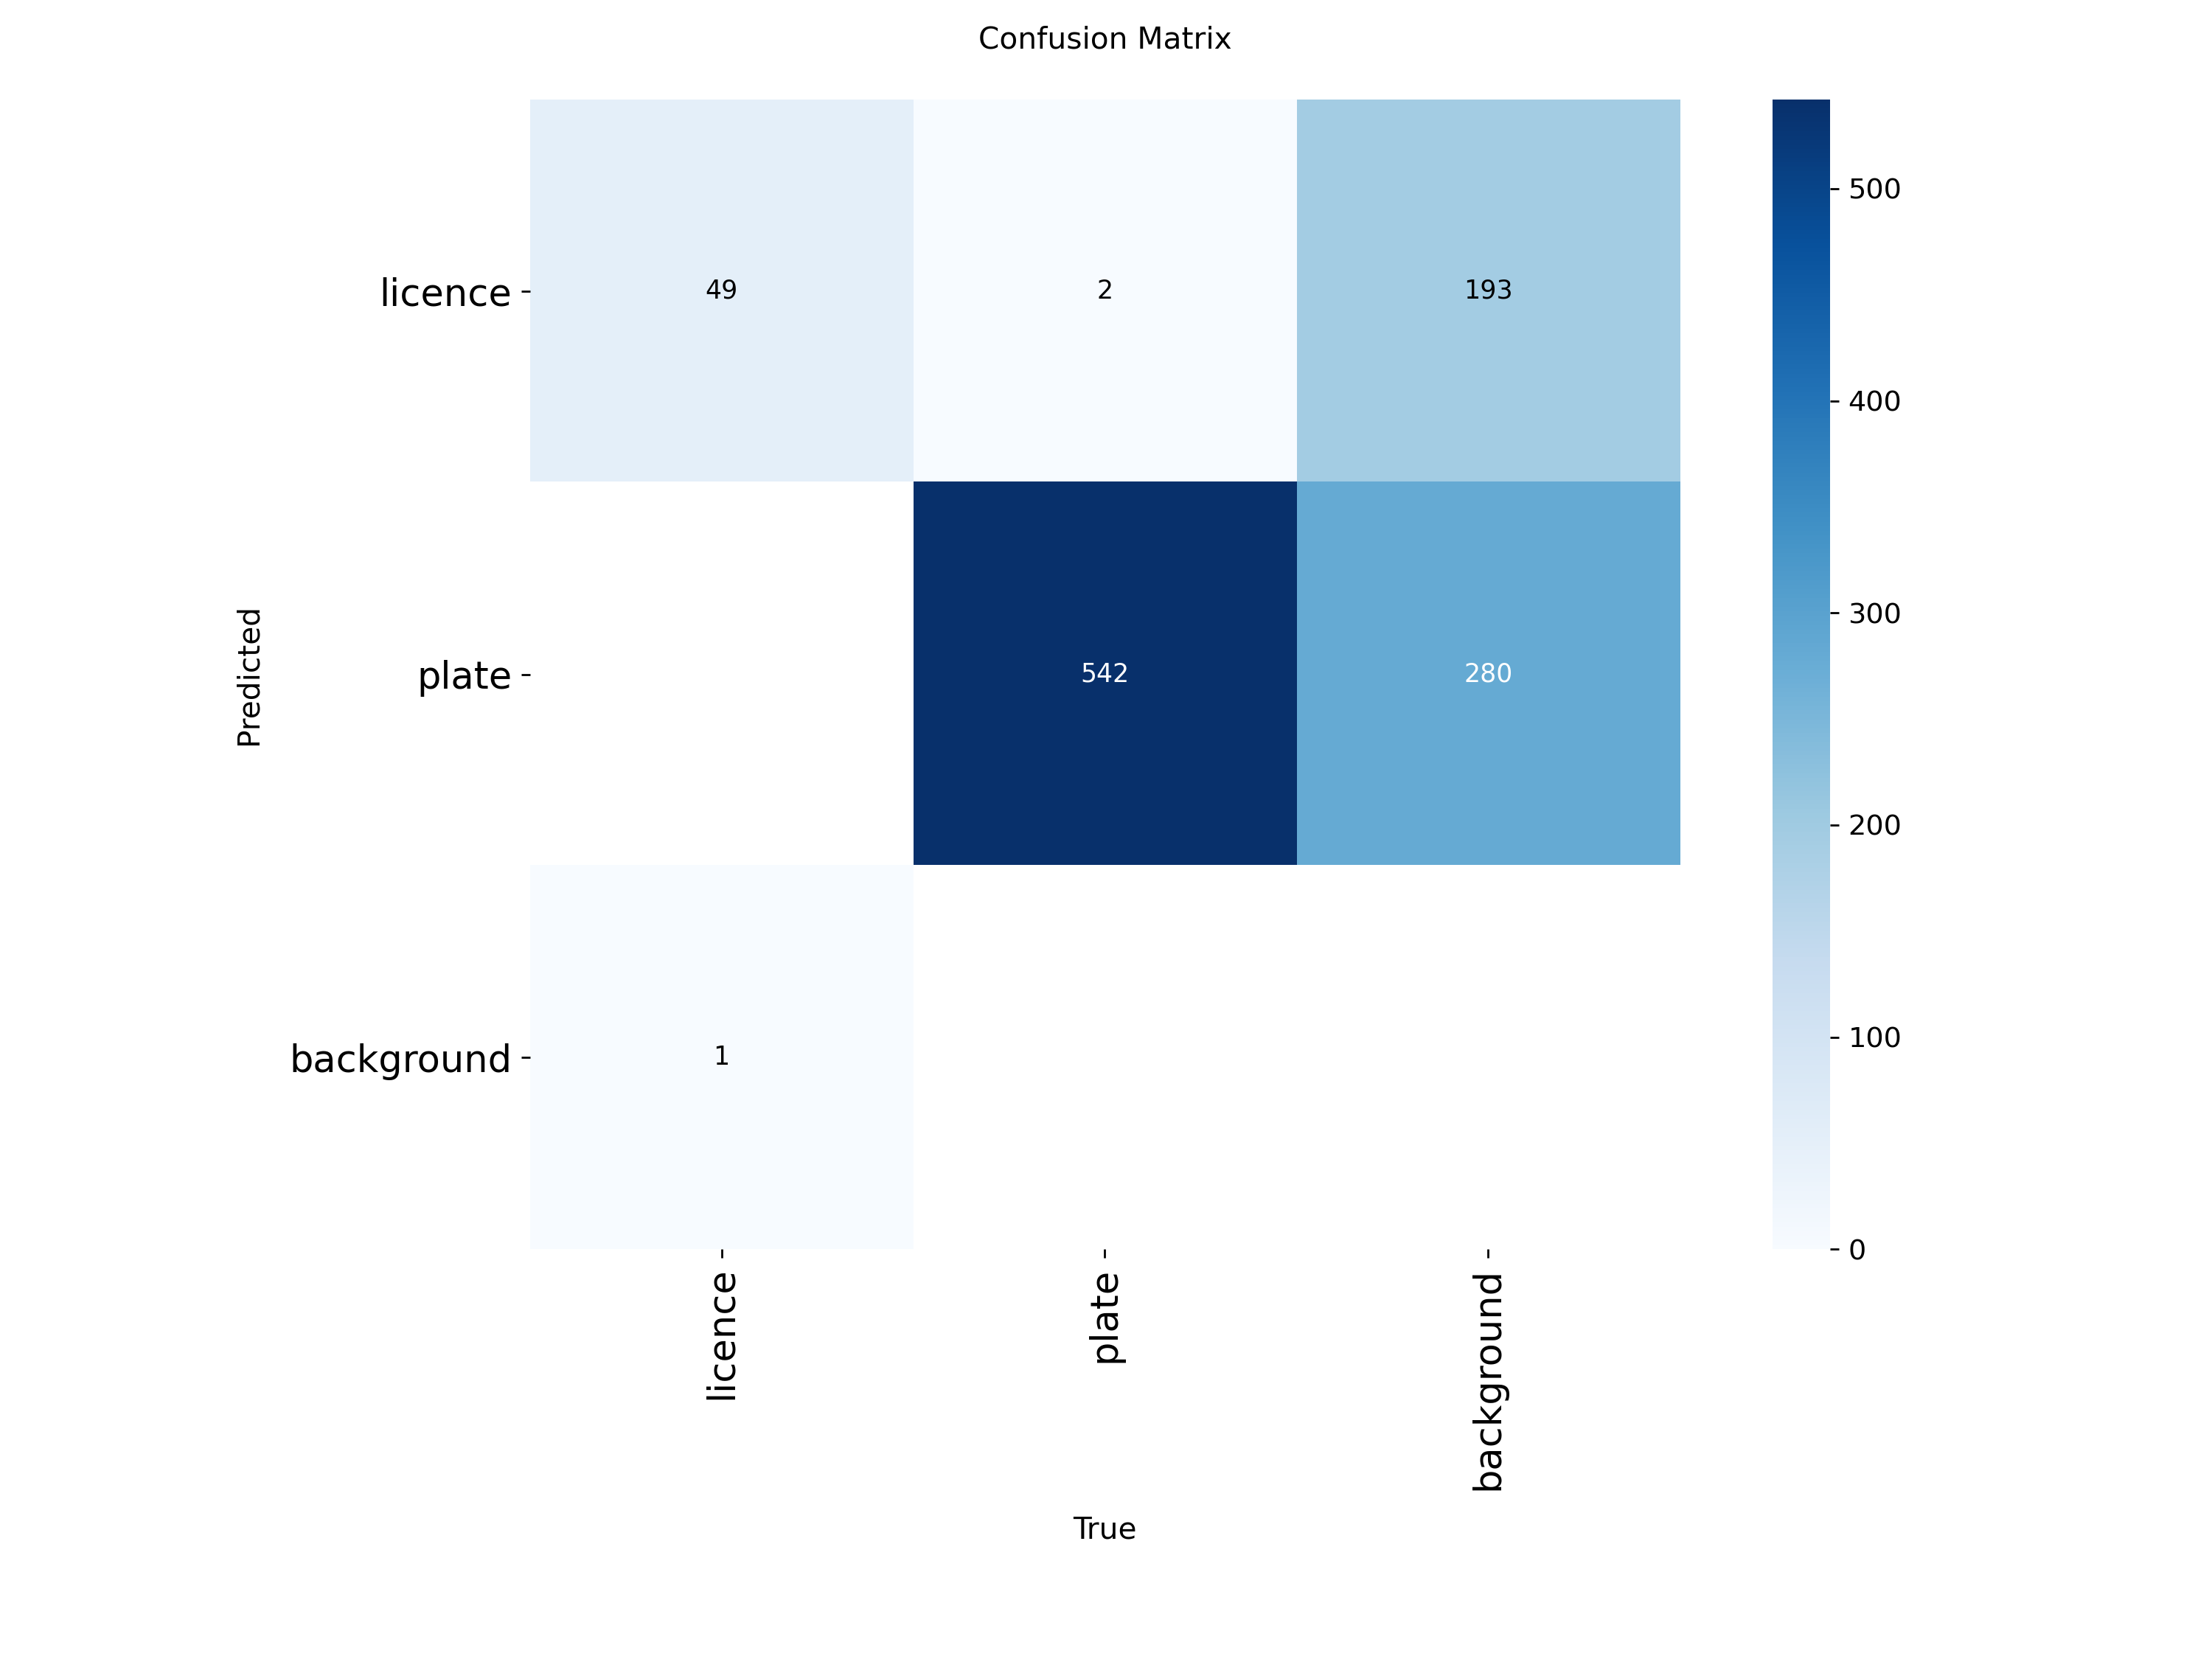

In [26]:
import os
from IPython.display import Image, display

for run in ['v8n', 'y26n']:
    print(f'\n===== {run.upper()} Training Curves & Performance Figures =====')
    for f in ['results.png', 'BoxPR_curve.png', 'PR_curve.png', 'confusion_matrix_normalized.png', 'confusion_matrix.png']:
        p = f'{OUT}/{run}/{f}'
        if os.path.exists(p):
            print(f'\n--- Showing: {f} ---')
            display(Image(p, width=800))
        else:
            print(f'[Info] {f} not found for {run}')

Saved validation comparison visualization to: /content/drive/MyDrive/edge_anpr/stage2/preds_YOLOv8n.png


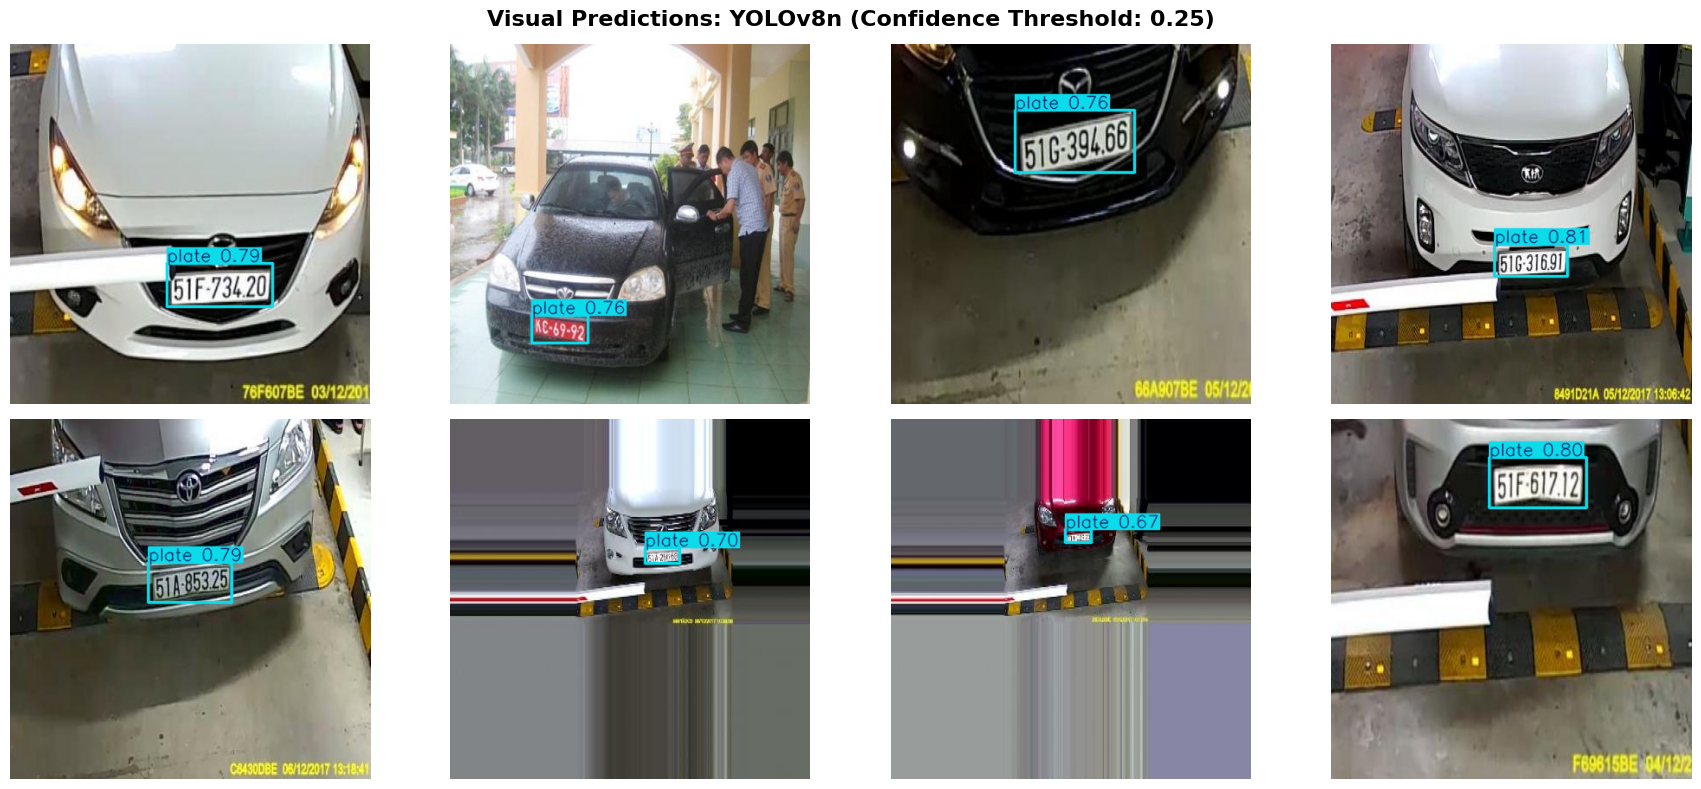

Saved validation comparison visualization to: /content/drive/MyDrive/edge_anpr/stage2/preds_YOLO26n.png


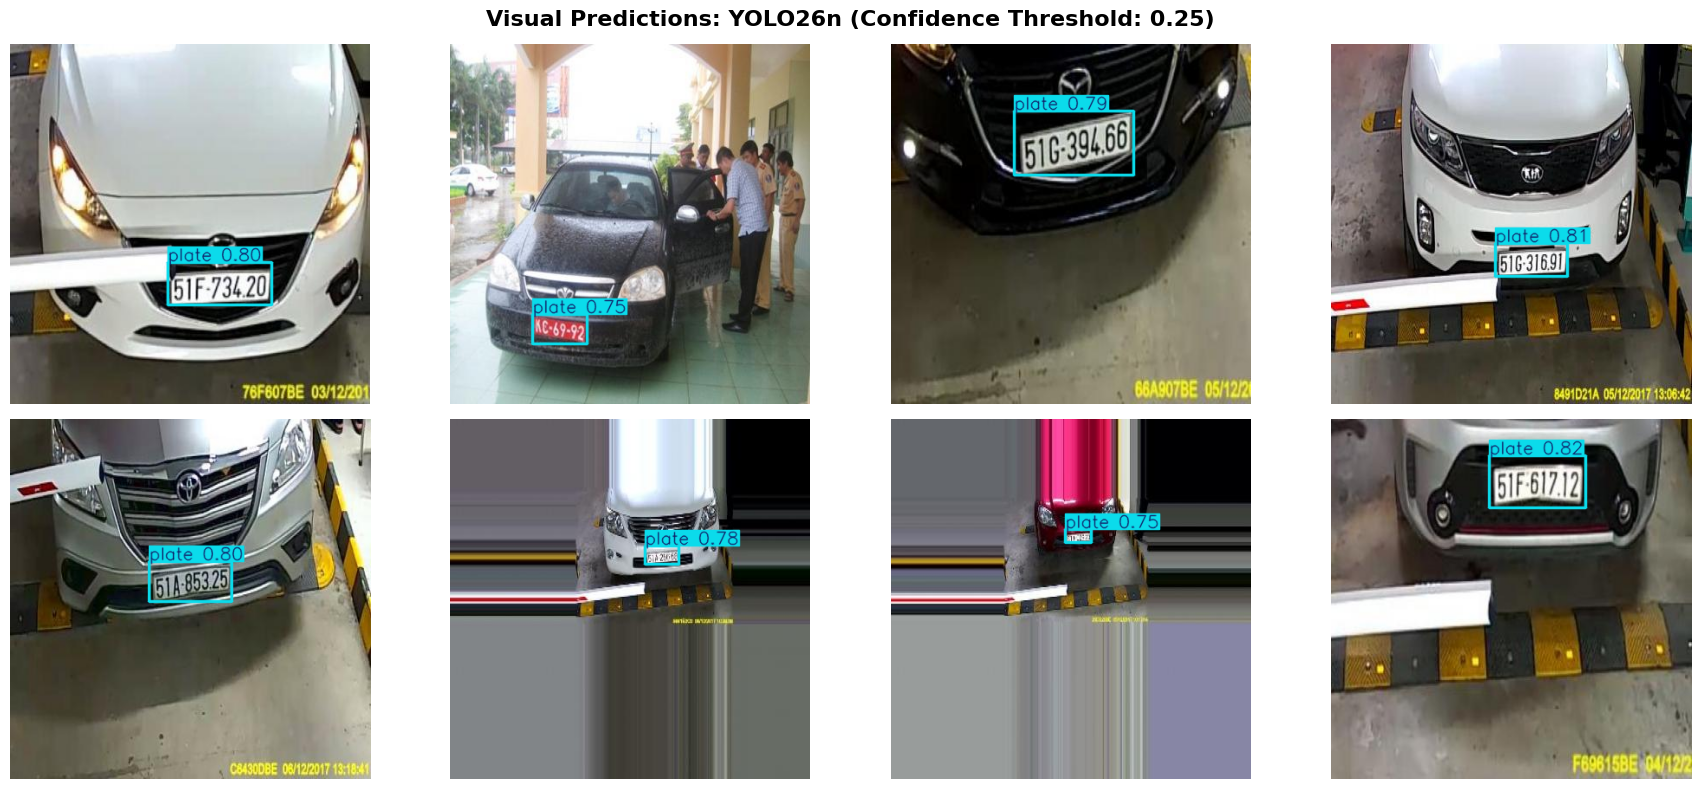

In [25]:
import random, cv2, glob
import matplotlib.pyplot as plt
from ultralytics import YOLO

random.seed(0)
sample = random.sample(sorted(glob.glob(f'{root}/test/images/*')), 8)

for mname, w in MODELS.items():
    model = YOLO(w)
    res = model.predict(sample, imgsz=640, conf=0.25, verbose=False)

    fig, axs = plt.subplots(2, 4, figsize=(18, 8))
    fig.suptitle(f'Visual Predictions: {mname} (Confidence Threshold: 0.25)', fontsize=16, weight='bold')

    for ax, r in zip(axs.ravel(), res):
        annotated_img = cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)
        ax.imshow(annotated_img)
        ax.axis('off')

    plt.tight_layout()
    out_img_path = f'{OUT}/preds_{mname}.png'
    plt.savefig(out_img_path, dpi=120)
    print(f'Saved validation comparison visualization to: {out_img_path}')
    plt.show()

## 11. Summary table
One table combining test accuracy, complexity, ONNX parity and CPU speed. Paste the output back to me — these are the numbers that go into the report.

In [28]:
test = acc[acc.split == 'test'].drop(columns='split')
summary = test.merge(cxdf, on='model').merge(pardf[['model', 'onnx_MB', 'mAP50_onnx']], on='model') \
              .merge(bdf[['model', 'mean_ms', 'fps']], on='model')
summary.to_csv(f'{OUT}/summary.csv', index=False)
print(summary.round(4).T.to_string())
print('\nAll files saved in', OUT)

                      0        1
model           YOLOv8n  YOLO26n
P                0.8689   0.8294
R                0.8274   0.8519
mAP50            0.8697   0.8373
mAP50_95         0.5148   0.5148
gpu_infer_ms     5.4363   5.6822
gpu_post_ms      2.8495   2.5655
mAP50_licence    0.7443   0.6796
mAP50_plate       0.995    0.995
layers              226      455
params_M         3.1382   2.5344
GFLOPs           8.7503     6.03
pt_MB            6.5046   5.4511
onnx_MB         12.7741   9.8533
mAP50_onnx       0.8561   0.8404
mean_ms        113.6051  90.5436
fps              8.8024  11.0444

All files saved in /content/drive/MyDrive/edge_anpr/stage2
